# COMP 472 Project: Comparing the four algorithms

This notebook compares the four required algorithms on **one shared validation split**. Each model's tuning is documented in its own notebook:

| Algorithm | Tuning notebook |
|---|---|
| k-Nearest Neighbours | `knn-kmean-Roham/knn_complete.ipynb` |
| Decision tree and random forest | `decision_tree_random_forest_sean/decision_tree_random_forest_gmm.ipynb` |
| Neural network | `nn_omar/nn_experiments.ipynb` |

Clustering has its own notebook: `clustering.ipynb`.

**How this notebook works**
1. Load the data and make the shared split (Sections 1 to 3).
2. Run each model with its chosen settings and save its validation predictions to Drive (Sections 5 to 8). If a model's predictions are already saved, its section is skipped, so a Colab disconnect only costs the section that was running.
3. Compare the saved predictions (Sections 9 to 12), then pick the final model and make the Kaggle submission (Sections 13 and 14).

**Runtime:** a GPU (Colab's T4) makes the neural network much faster, but every section also runs on the CPU. k-NN, the tree and the forest always run on the CPU.

## 1. Setup
Mount Drive, unzip the dataset, and set the folder where predictions and results are saved.

In [56]:
from google.colab import drive
drive.mount('/content/drive')

ZIP_PATH = '/content/drive/MyDrive/comp472/comp-472-project-fall-2026-concordia.zip'
DATA_DIR = '/content/data'
OUT_DIR = '/content/drive/MyDrive/comp472/comparison'    # saved predictions and results go here

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [57]:
import os, glob, zipfile, time
import numpy as np
import pandas as pd

os.makedirs(DATA_DIR, exist_ok=True)
os.makedirs(OUT_DIR, exist_ok=True)
with zipfile.ZipFile(ZIP_PATH) as z:
    z.extractall(DATA_DIR)

def find_csv(name):
    """Find a CSV anywhere inside the extracted zip (handles nested folders)."""
    hits = [p for p in glob.glob(f'{DATA_DIR}/**/{name}', recursive=True) if '__MACOSX' not in p]
    if not hits:
        raise FileNotFoundError(f'{name} not found under {DATA_DIR}')
    return hits[0]

SEED = 42
TASKS = ['image', 'sentiment']

## 2. Load the data
Each task keeps its row ids, so every saved prediction can be matched back to its row.

In [58]:
def load_task(task):
    """Training ids, features and labels, plus test ids and features, for one task."""
    train = pd.read_csv(find_csv(f'{task}_train.csv'))
    test = pd.read_csv(find_csv(f'{task}_test.csv'))
    feat_cols = [c for c in train.columns if c.startswith('feature_')]
    return dict(
        ids=train['id'].to_numpy(),
        X=train[feat_cols].to_numpy(),
        y=train['label'].to_numpy(),
        test_ids=test['id'].to_numpy(),
        X_test=test[feat_cols].to_numpy(),
        n_classes=int(train['label'].max()) + 1,
    )

data = {task: load_task(task) for task in TASKS}
for task in TASKS:
    d = data[task]
    print(f"{task:9s} | train {d['X'].shape} | test {d['X_test'].shape} | classes {d['n_classes']}")

image     | train (20000, 500) | test (5000, 500) | classes 50
sentiment | train (12000, 768) | test (5000, 768) | classes 3


## 3. The shared validation split
Every model in this notebook is trained on the same 80% and evaluated on the same 20%.

The split uses `stratified_split` from the neural network notebook, unchanged, with the same seed (42), so it picks exactly the same rows as that notebook. *Stratified* means 20% of **each class** goes to validation, so both parts keep the class balance: 80 validation rows per image class and 800 per sentiment class.

The validation ids are also saved to Drive. When this cell runs again, it checks that the split still matches the saved file.

Each model fits its feature scaling (mean, standard deviation, etc.) on the training part only.

In [59]:
def stratified_split(y, val_frac=0.2, seed=42):
    """Hold out val_frac of every class so both splits keep the class balance.
    Copied unchanged from nn_experiments.ipynb."""
    rng = np.random.default_rng(seed)
    tr_idx, va_idx = [], []
    for c in np.unique(y):
        idx = np.where(y == c)[0]
        rng.shuffle(idx)
        n_val = int(round(len(idx) * val_frac))
        va_idx.append(idx[:n_val])
        tr_idx.append(idx[n_val:])
    return np.concatenate(tr_idx), np.concatenate(va_idx)

split = {}
for task in TASKS:
    tr, va = stratified_split(data[task]['y'], val_frac=0.2, seed=SEED)
    split[task] = dict(tr=tr, va=va)

# checks: no row in both parts, no row missing, same number of validation rows per class
for task in TASKS:
    d, tr, va = data[task], split[task]['tr'], split[task]['va']
    assert len(np.intersect1d(tr, va)) == 0, 'a row is in both parts'
    assert len(tr) + len(va) == len(d['y']), 'a row is missing'
    per_class = np.bincount(d['y'][va], minlength=d['n_classes'])
    assert per_class.min() == per_class.max(), 'validation classes are not balanced'
    print(f'{task:9s} | train {len(tr)} | validation {len(va)} | validation rows per class {per_class[0]}')

image     | train 16000 | validation 4000 | validation rows per class 80
sentiment | train 9600 | validation 2400 | validation rows per class 800


In [60]:
# save the validation ids, or check that the split matches the ids saved earlier
for task in TASKS:
    path = os.path.join(OUT_DIR, f'val_ids_{task}.csv')
    ids = data[task]['ids'][split[task]['va']]
    if os.path.exists(path):
        saved = pd.read_csv(path)['id'].to_numpy()
        assert np.array_equal(saved, ids), f'the split does not match {path}'
        print(f'{task:9s} | split matches the saved ids: {path}')
    else:
        pd.DataFrame({'id': ids}).to_csv(path, index=False)
        print(f'{task:9s} | saved validation ids: {path}')

image     | split matches the saved ids: /content/drive/MyDrive/comp472/comparison/val_ids_image.csv
sentiment | split matches the saved ids: /content/drive/MyDrive/comp472/comparison/val_ids_sentiment.csv


In [61]:
def get_split(task):
    """X_train, y_train, X_val, y_val for one task, from the shared split."""
    d, s = data[task], split[task]
    return d['X'][s['tr']], d['y'][s['tr']], d['X'][s['va']], d['y'][s['va']]

## 4. Saving results
Every model section saves two things to `OUT_DIR`:

- **Validation predictions**, one file per model and task: `val_preds_<model>_<task>.csv`, with columns `id, true_label, pred_label`, plus `prob_0, prob_1, ...` when the model gives class probabilities. For k-NN and the random forest, the probabilities are the share of votes for each class. Sections 9 to 13 only read these files.
- **One row in `results.csv`**: training accuracy, validation accuracy, training time, prediction time and the settings used. The comparison table and the timing table are built from it.

If a model's prediction file already exists, `already_done` returns True and that model's section skips it. To rerun a model, delete its file.

In [62]:
MODELS = ['knn', 'tree', 'forest', 'nn']
RESULTS_PATH = os.path.join(OUT_DIR, 'results.csv')

def pred_path(model_name, task):
    return os.path.join(OUT_DIR, f'val_preds_{model_name}_{task}.csv')

def already_done(model_name, task):
    """True if this model's validation predictions are already saved."""
    path = pred_path(model_name, task)
    if os.path.exists(path):
        print(f'{model_name} / {task}: already saved, skipping ({path})')
        return True
    return False

def save_predictions(model_name, task, pred, probs=None):
    """Save validation predictions: id, true_label, pred_label, and prob_0, prob_1, ... if given."""
    d, va = data[task], split[task]['va']
    pred = np.asarray(pred).astype(int)
    assert len(pred) == len(va), 'need one prediction per validation row, in split order'
    table = pd.DataFrame({'id': d['ids'][va], 'true_label': d['y'][va], 'pred_label': pred})
    if probs is not None:
        probs = np.asarray(probs, dtype=float)
        assert probs.shape == (len(va), d['n_classes']), 'probs needs one row per example, one column per class'
        assert np.allclose(probs.sum(axis=1), 1, atol=1e-3), 'each row of probs should add up to 1'
        for c in range(d['n_classes']):
            table[f'prob_{c}'] = probs[:, c]
    table.to_csv(pred_path(model_name, task), index=False)
    val_acc = float(np.mean(pred == d['y'][va]))
    print(f'{model_name} / {task}: validation accuracy {val_acc:.4f}, saved to {pred_path(model_name, task)}')
    return val_acc

def log_result(model_name, task, train_acc, val_acc, fit_seconds, predict_seconds, settings=''):
    """Add one row to results.csv, replacing any older row for the same model and task.
    train_acc can be None if it is too slow to compute (k-NN)."""
    row = pd.DataFrame([dict(model=model_name, task=task, train_acc=train_acc, val_acc=val_acc,
                             fit_seconds=round(fit_seconds, 1), predict_seconds=round(predict_seconds, 1),
                             settings=settings)])
    if os.path.exists(RESULTS_PATH):
        old = pd.read_csv(RESULTS_PATH)
        old = old[~((old['model'] == model_name) & (old['task'] == task))]
        row = pd.concat([old, row], ignore_index=True)
    row.to_csv(RESULTS_PATH, index=False)

def load_predictions(model_name, task):
    return pd.read_csv(pred_path(model_name, task))

def show_status():
    """Which models have saved predictions so far."""
    status = pd.DataFrame({task: ['saved' if os.path.exists(pred_path(m, task)) else '-' for m in MODELS]
                           for task in TASKS}, index=MODELS)
    print(status)

show_status()

        image sentiment
knn     saved     saved
tree    saved     saved
forest  saved     saved
nn      saved     saved


## 5. k-Nearest Neighbours
Code from `knn_complete.ipynb`, written with NumPy (the coding rules allow PyTorch only for the neural network).

The sweep runs here, on the shared split. It tries every combination of:
- **feature scaling:** none, standardize, and one per task (square root for the image histograms, PCA whitening for sentiment)
- **distance:** Euclidean, Manhattan, Minkowski (p = 3), cosine
- **voting:** majority, or weighted (closer neighbours count more)
- **k:** 1 to 200 for image, 1 to 4,000 for sentiment (see 5.4 for why they differ)

**Run time:** about 15 minutes in total on Colab's CPU (measured on a 2-core machine like Colab's). Results are saved as they finish, so a disconnect only loses the setting being computed.

### 5.1 Distance functions (NumPy)
The same four functions as Section 3 of `knn_complete.ipynb`, with the same inputs and outputs. For p = 3, Minkowski multiplies `diff * diff * diff` instead of computing `diff ** 3`: same result, faster.

In [63]:
def euclidean_distance(x, X):
    return np.sqrt(np.sum((X - x) ** 2, axis=1))

def manhattan_distance(x, X):
    return np.sum(np.abs(X - x), axis=1)

def minkowski_distance(x, X, p=3):
    diff = np.abs(X - x)
    if p == 3:
        powered = diff * diff * diff    # same as diff ** 3, but several times faster
    else:
        powered = diff ** p
    return np.sum(powered, axis=1) ** (1 / p)

def cosine_distance(x, X):
    lengths = np.linalg.norm(X, axis=1) * np.linalg.norm(x)
    lengths[lengths == 0] = 1e-12
    return 1 - (X @ x) / lengths

### 5.2 Feature scaling
Copied unchanged from Section 4 of `knn_complete.ipynb`. Each function learns from the training rows only and applies the same change to the other rows.

In [64]:
from sklearn.decomposition import PCA    # preprocessing only, not the k-NN algorithm itself

def no_scaling(X_train, X_other):
    return X_train, X_other

def standardize(X_train, X_other):
    #mean and std come from the training rows only
    mean = X_train.mean(axis=0)
    std = X_train.std(axis=0)
    std[std == 0] = 1
    return (X_train - mean) / std, (X_other - mean) / std

def sqrt_scaling(X_train, X_other):
    #for the image histograms: shrinks big counts so rare visual words matter too
    A = np.sqrt(X_train)
    B = np.sqrt(X_other)
    len_A = np.linalg.norm(A, axis=1, keepdims=True)
    len_B = np.linalg.norm(B, axis=1, keepdims=True)
    len_A[len_A == 0] = 1
    len_B[len_B == 0] = 1
    return A / len_A, B / len_B

def pca_whiten(X_train, X_other, n_components=64):
    #squeezes 768 features to 64 and gives each the same spread
    pca = PCA(n_components, whiten=True, random_state=SEED)
    pca.fit(X_train)
    return pca.transform(X_train), pca.transform(X_other)

### 5.3 The k-NN model
The `KNN` class is copied unchanged from Section 5 of `knn_complete.ipynb`. It is used again in Section 14 for the final model.

Two helper functions split its `predict_all_k` method into the two steps it already does:
- `nearest_neighbours`: for each validation row, compute the distance to every training row and keep the closest `max_k` (the slow step)
- `knn_vote`: from those saved neighbours, vote with the first k, using the class's own `_vote`. With `with_shares=True` it also returns each class's share of the votes, which serve as the class probabilities

In [65]:
from collections import Counter

class KNN:
    def __init__(self, k = 1, distance_fn = euclidean_distance, weighted = False):
        self.k = k
        self.distance_fn = distance_fn
        self.weighted = weighted

    def fit(self, X_train, y_train):
        self.X_train = X_train
        self.y_train= y_train
        return self

    def _vote(self, labels, dists, weighted):
        if weighted:
            #closer neighbours get a bigger vote, add the votes up per label
            weights = 1 / (dists + 1e-9)
            return np.bincount(labels, weights=weights).argmax()
        return Counter(labels).most_common(1)[0][0]

    def _predict(self, x):
        dists = self.distance_fn(x, self.X_train)
        nearest = np.argsort(dists)[:self.k]
        return self._vote(self.y_train[nearest], dists[nearest], self.weighted)

    def predict(self, X):
        prediction = [self._predict(x) for x in X]
        return prediction

    def score(self, X, y):
        preds = self.predict(X)
        return sum(p == t for p, t in zip(preds, y)) / len(y)

    def predict_all_k(self, X, k_values):
        #same as predict, but the distances and sorting are done once per row
        #and reused for every k, instead of redoing them for each k
        #returns two dicts: normal vote and weighted vote
        unweighted_preds = {k: [] for k in k_values}
        weighted_preds = {k: [] for k in k_values}
        for x in X:
            dists = self.distance_fn(x, self.X_train)
            nearest = np.argsort(dists)[:max(k_values)]
            for k in k_values:
                labels = self.y_train[nearest[:k]]
                near_dists = dists[nearest[:k]]
                unweighted_preds[k].append(self._vote(labels, near_dists, False))
                weighted_preds[k].append(self._vote(labels, near_dists, True))
        return unweighted_preds, weighted_preds

In [66]:
def nearest_neighbours(X_train, X_query, distance_fn, max_k):
    """For each query row: the indices and distances of its max_k nearest training rows, closest first."""
    idx = np.empty((len(X_query), max_k), dtype=np.int64)
    dist = np.empty((len(X_query), max_k))
    for i, x in enumerate(X_query):
        d = distance_fn(x, X_train)
        nearest = np.argsort(d)[:max_k]
        idx[i], dist[i] = nearest, d[nearest]
    return idx, dist

def knn_vote(y_train, idx, dist, k, weighted, n_classes, with_shares=False):
    """Vote with each row's first k neighbours. Returns the predictions,
    and each class's share of the votes if with_shares=True."""
    voter = KNN()
    preds = np.empty(len(idx), dtype=int)
    shares = np.zeros((len(idx), n_classes)) if with_shares else None
    for i in range(len(idx)):
        labels, d = y_train[idx[i, :k]], dist[i, :k]
        preds[i] = voter._vote(labels, d, weighted)
        if with_shares:
            w = 1 / (d + 1e-9) if weighted else np.ones(k)
            shares[i] = np.bincount(labels, weights=w, minlength=n_classes) / w.sum()
    return preds, shares

### 5.4 Sweep on the shared split
For each scaling and distance, the slow step finds every validation row's nearest training rows once. Every k and both voting types are then scored from that one neighbour list. Each result is saved to `OUT_DIR/knn_sweep_parts` as soon as it finishes, so a rerun skips the finished ones. The full table is saved as `sweep_knn_<task>.csv` for the plots in Section 12.

**Why the k lists differ:** on image, accuracy is highest at k = 1 and falls as k grows, so 200 is far enough. On sentiment it keeps rising long past 200 and levels off around k = 2,000 to 3,000 (a quarter to a third of the training rows), so its list goes up to 4,000 to show where it stops improving.

Features are converted to 32-bit floats before the distances are computed, which is about twice as fast.

In [67]:
K_VALUES = {
    'image':     [1, 3, 5, 10, 20, 35, 50, 75, 100, 150, 200],
    'sentiment': [1, 3, 5, 10, 20, 35, 50, 75, 100, 150, 200, 300, 400, 600, 1000, 1500, 2000, 3000, 4000],
}
DISTANCES = [euclidean_distance, manhattan_distance, minkowski_distance, cosine_distance]
KNN_SCALINGS = {
    'image':     [('none', no_scaling), ('standardize', standardize), ('sqrt', sqrt_scaling)],
    'sentiment': [('none', no_scaling), ('standardize', standardize), ('pca_whiten', pca_whiten)],
}
PARTS_DIR = os.path.join(OUT_DIR, 'knn_sweep_parts')
os.makedirs(PARTS_DIR, exist_ok=True)

def get_neighbours(task, scaling_name, distance_fn):
    """For one scaling and distance: each validation row's nearest training rows
    (as many as the largest k), their distances, and how long the search took."""
    X_tr, y_tr, X_va, y_va = get_split(task)
    scaling_fn = dict(KNN_SCALINGS[task])[scaling_name]
    X_a, X_b = scaling_fn(X_tr, X_va)                  # learned on the training part only
    X_a, X_b = X_a.astype(np.float32), X_b.astype(np.float32)
    start = time.time()
    idx, dist = nearest_neighbours(X_a, X_b, distance_fn, max(K_VALUES[task]))
    return idx, dist, time.time() - start

knn_sweeps = {}
for task in TASKS:
    _, y_tr, _, y_va = get_split(task)
    parts = []
    for scaling_name, _ in KNN_SCALINGS[task]:
        for distance_fn in DISTANCES:
            part_path = os.path.join(PARTS_DIR, f'{task}_{scaling_name}_{distance_fn.__name__}.csv')
            if os.path.exists(part_path):
                part = pd.read_csv(part_path)
                note = 'saved earlier'
            else:
                idx, dist, seconds = get_neighbours(task, scaling_name, distance_fn)
                rows = []
                for voting in ['majority', 'weighted']:
                    for k in K_VALUES[task]:
                        preds, _ = knn_vote(y_tr, idx, dist, k, voting == 'weighted', data[task]['n_classes'])
                        rows.append(dict(scaling=scaling_name, distance=distance_fn.__name__, voting=voting, k=k,
                                         val_acc=round(float(np.mean(preds == y_va)), 4),
                                         search_seconds=round(seconds, 1)))
                part = pd.DataFrame(rows)
                part.to_csv(part_path, index=False)
                note = f'search {seconds:.0f} s'
            best = part.loc[part['val_acc'].idxmax()]
            print(f"{task:9s} | {scaling_name:11s} | {distance_fn.__name__:18s} | "
                  f"best: {best['voting']} k={best['k']}, val acc {best['val_acc']:.4f} | {note}")
            parts.append(part)
    knn_sweeps[task] = pd.concat(parts, ignore_index=True)
    knn_sweeps[task].to_csv(os.path.join(OUT_DIR, f'sweep_knn_{task}.csv'), index=False)

image     | none        | euclidean_distance | best: majority k=1, val acc 0.5192 | saved earlier
image     | none        | manhattan_distance | best: majority k=1, val acc 0.4045 | saved earlier
image     | none        | minkowski_distance | best: majority k=1, val acc 0.4158 | saved earlier
image     | none        | cosine_distance    | best: majority k=1, val acc 0.5192 | saved earlier
image     | standardize | euclidean_distance | best: majority k=1, val acc 0.4300 | saved earlier
image     | standardize | manhattan_distance | best: majority k=1, val acc 0.3093 | saved earlier
image     | standardize | minkowski_distance | best: majority k=1, val acc 0.3977 | saved earlier
image     | standardize | cosine_distance    | best: majority k=1, val acc 0.5333 | saved earlier
image     | sqrt        | euclidean_distance | best: majority k=1, val acc 0.5627 | saved earlier
image     | sqrt        | manhattan_distance | best: majority k=1, val acc 0.4597 | saved earlier
image     | sqrt    

### 5.5 Sweep summary
The best k for each scaling, distance and voting type, best first. Differences smaller than about 1.5 points (image) or 2 points (sentiment) can be chance, so several settings at the top may be tied.

In [68]:
for task in TASKS:
    sweep = knn_sweeps[task]
    best_k = sweep.loc[sweep.groupby(['scaling', 'distance', 'voting'])['val_acc'].idxmax()]
    print(f'=== {task} ===')
    print(best_k.sort_values('val_acc', ascending=False)
                .drop(columns='search_seconds').head(10).to_string(index=False))
    print()

=== image ===
    scaling           distance   voting  k  val_acc
       sqrt euclidean_distance weighted  1   0.5627
       sqrt euclidean_distance majority  1   0.5627
       sqrt    cosine_distance weighted  1   0.5627
       sqrt    cosine_distance majority  1   0.5627
standardize    cosine_distance majority  1   0.5333
standardize    cosine_distance weighted  1   0.5333
       none    cosine_distance majority  1   0.5192
       none    cosine_distance weighted  1   0.5192
       none euclidean_distance weighted  1   0.5192
       none euclidean_distance majority  1   0.5192

=== sentiment ===
    scaling           distance   voting    k  val_acc
 pca_whiten    cosine_distance weighted 3000   0.6471
 pca_whiten    cosine_distance majority 3000   0.6458
standardize    cosine_distance weighted   75   0.5921
 pca_whiten euclidean_distance majority  100   0.5908
standardize    cosine_distance majority   35   0.5908
 pca_whiten euclidean_distance weighted  100   0.5904
       none    co

### 5.6 Best setting: save its predictions
The setting with the highest validation accuracy is kept. Its neighbours are found once more (under a minute), and its validation predictions are saved with the vote shares as class probabilities.

Training accuracy is not computed: it would mean finding neighbours for all 16,000 training rows, and at k = 1 it is 100% by definition (each row is its own nearest neighbour). Training time is recorded as 0, because fitting k-NN only stores the training rows.

In [69]:
MODEL = 'knn'
distance_by_name = {fn.__name__: fn for fn in DISTANCES}
for task in TASKS:
    if already_done(MODEL, task):
        continue
    sweep = knn_sweeps[task]
    best = sweep.loc[sweep['val_acc'].idxmax()]
    _, y_tr, _, _ = get_split(task)
    idx, dist, seconds = get_neighbours(task, best['scaling'], distance_by_name[best['distance']])
    preds, shares = knn_vote(y_tr, idx, dist, int(best['k']), best['voting'] == 'weighted',
                             data[task]['n_classes'], with_shares=True)
    settings = f"scaling={best['scaling']}, distance={best['distance']}, voting={best['voting']}, k={int(best['k'])}"
    print(f'{task}: {settings}')
    val_acc = save_predictions(MODEL, task, preds, shares)
    log_result(MODEL, task, train_acc=None, val_acc=val_acc, fit_seconds=0.0,
               predict_seconds=seconds, settings=settings)
show_status()

knn / image: already saved, skipping (/content/drive/MyDrive/comp472/comparison/val_preds_knn_image.csv)
knn / sentiment: already saved, skipping (/content/drive/MyDrive/comp472/comparison/val_preds_knn_sentiment.csv)
        image sentiment
knn     saved     saved
tree    saved     saved
forest  saved     saved
nn      saved     saved


## 6. Decision tree
Code from `decision_tree_random_forest_gmm.ipynb`. The function cell (6.1) is also used by the random forest in Section 7.

The tree sweeps are quick, so they run again here on the shared split, with the same settings grid as in `decision_tree_random_forest_gmm.ipynb`. The best setting is then picked from this rerun, the same way as for k-NN. One extra sweep (6.3) grows trees with no limit on node size, to show overfitting clearly.

**Run time:** about 1 minute for sentiment and 10 minutes for image.

### 6.1 Tree and forest functions
Copied from `decision_tree_random_forest_gmm.ipynb`, unchanged except for one addition: `tree_depth_sweep` takes an optional `train_out` dictionary and stores each setting's training accuracy in it, the same way `truncated_forest_grid` already does. The original only printed it. The plots in Section 12 need it.

See the markdown cell above the function cell in `decision_tree_random_forest_gmm.ipynb` for what each function does.

In [70]:
def gini_func(labels):

    _, count = np.unique(labels, return_counts=True)
    total = len(labels)

    proportion = count/total
    proportion_squared = proportion**2

    sum_of_proportions_squared = proportion_squared.sum()

    return 1 - sum_of_proportions_squared;

def split_search(inputs, output, feature_indices=None):
    best_score = float("inf")
    best_feature = None
    best_threshold = None

    if feature_indices is None:
        feature_indices = range(inputs.shape[1])

    count_labels = output.max() + 1
    onehot = np.eye(count_labels)[output]

    n = len(output)
    left_sizes = np.arange(1, n + 1)
    right_sizes = n - left_sizes

    for j in feature_indices:
        values = inputs[:, j]
        order = values.argsort()
        sorted_values = values[order]
        identity = onehot[order]

        running_total = np.cumsum(identity, axis=0)
        total_counts = running_total[-1]
        right_counts = (total_counts - running_total)[:-1]

        left_gini = 1 - np.sum((running_total / left_sizes[:, None]) ** 2, axis=1)
        right_gini = 1 - np.sum((right_counts / right_sizes[:-1][:, None]) ** 2, axis=1)

        weighted = (left_sizes[:-1] * left_gini[:-1] + right_sizes[:-1] * right_gini) / n

        mask = sorted_values[:-1] != sorted_values[1:]
        weighted = np.where(mask, weighted, np.inf)

        i = np.argmin(weighted)
        if weighted[i] < best_score:
            best_score = weighted[i]
            best_feature = j
            best_threshold = (sorted_values[i] + sorted_values[i + 1]) / 2

    return best_feature, best_threshold, best_score

def decision_tree(inputs, output, depth, max_depth, min_gain=0.001, min_rows=2, n_features=None):

    if len(np.unique(output)) == 1 or depth >= max_depth or len(output) < min_rows:
        return np.bincount(output).argmax()

    parent_gini = gini_func(output)

    if n_features is None:
        feature_subset = None
    else:
        feature_subset = np.random.choice(inputs.shape[1], n_features, replace=False)

    child_best_feature, child_best_threshold, child_best_score = split_search(inputs, output, feature_subset)

    current_gain = parent_gini - child_best_score

    if current_gain < min_gain:
        return np.bincount(output).argmax()

    left_child = inputs[:, child_best_feature] <= child_best_threshold
    right_child = inputs[:, child_best_feature] > child_best_threshold

    left_subtree = decision_tree(inputs[left_child], output[left_child], depth + 1, max_depth, min_gain, min_rows, n_features)

    right_subtree = decision_tree(inputs[right_child], output[right_child], depth + 1, max_depth, min_gain, min_rows, n_features)

    return {"feature" : child_best_feature, "threshold" :child_best_threshold, "left" : left_subtree, "right" : right_subtree}

def predict_batch(tree, inputs):
    if not isinstance(tree, dict):
        return np.full(len(inputs), tree)
    left = inputs[:, tree["feature"]] <= tree["threshold"]
    preds = np.empty(len(inputs), dtype=int)
    preds[left] = predict_batch(tree["left"], inputs[left])
    preds[~left] = predict_batch(tree["right"], inputs[~left])
    return preds

def accuracy(pred, y):
    return np.mean(pred == y)

def tree_depth_sweep(train_X, train_Y, val_X, val_Y, min_rows_list, min_gain_list, depths, train_out=None):
    results = {}
    deepest = max(depths)
    for mr in min_rows_list:
        for mg in min_gain_list:
            tree = decision_tree(train_X, train_Y, depth=0, max_depth=deepest, min_gain=mg, min_rows=mr)
            add_majority(tree, train_X, train_Y)
            for d in depths:
                cut = truncate(tree, d)
                val_acc = accuracy(predict_batch(cut, val_X), val_Y)
                train_acc = accuracy(predict_batch(cut, train_X), train_Y)
                results[(mr, mg, d)] = val_acc
                if train_out is not None:      # added: keep training accuracy too, as truncated_forest_grid does
                    train_out[(mr, mg, d)] = train_acc
                print(f"min_rows {mr}, min_gain {mg}, depth {d}: val {val_acc:.4f}, train {train_acc:.4f}")
    return results

def add_majority(tree, X, Y, fallback=0):
    if not isinstance(tree, dict):
        return
    tree["majority"] = np.bincount(Y).argmax() if len(Y) > 0 else fallback
    left = X[:, tree["feature"]] <= tree["threshold"]
    add_majority(tree["left"], X[left], Y[left], tree["majority"])
    add_majority(tree["right"], X[~left], Y[~left], tree["majority"])

def truncate(tree, max_depth, depth=0):
    if not isinstance(tree, dict):
        return tree
    if depth == max_depth:
        return tree["majority"]
    return {"feature": tree["feature"], "threshold": tree["threshold"],
            "left": truncate(tree["left"], max_depth, depth + 1),
            "right": truncate(tree["right"], max_depth, depth + 1)}
def bootstrap_sample(inputs, output):
    idx = np.random.randint(0, len(inputs), size=len(inputs))
    return inputs[idx], output[idx]

def random_forest(inputs, output, n_trees, n_features, max_depth, min_rows, min_gain):
    forest = []
    for tree in range(n_trees):
        X, Y = bootstrap_sample(inputs, output)
        seedling = decision_tree(X, Y, depth=0, max_depth=max_depth, min_rows=min_rows,
                                 min_gain=min_gain, n_features=n_features)
        forest.append(seedling)
    return forest

def forest_predict_batch(trees, inputs, n_classes):
    votes = np.stack([predict_batch(t, inputs) for t in trees])
    counts = np.apply_along_axis(np.bincount, 0, votes, minlength=n_classes)
    return counts.argmax(axis=0)

def build_forest_with_majority(train_X, train_Y, n_trees, n_features, max_depth, min_rows, min_gain):
    forest = []
    for _ in range(n_trees):
        X, Y = bootstrap_sample(train_X, train_Y)
        tree = decision_tree(X, Y, depth=0, max_depth=max_depth, min_rows=min_rows,
                             min_gain=min_gain, n_features=n_features)
        add_majority(tree, X, Y)
        forest.append(tree)
    return forest

def truncated_forest_grid(train_X, train_Y, val_X, val_Y, n_trees_list, n_features_list,
                          depths, min_rows, min_gain=0.0, seed=42, train_out=None):
    results = {}
    n_classes = train_Y.max() + 1
    deepest = max(depths)
    for nf in n_features_list:
        np.random.seed(seed)
        forest = build_forest_with_majority(train_X, train_Y, max(n_trees_list), nf,
                                            deepest, min_rows, min_gain)
        for d in depths:
            trunc = [truncate(t, d) for t in forest]
            for nt in n_trees_list:
                key = (d, min_rows, nt, nf)
                val_acc = accuracy(forest_predict_batch(trunc[:nt], val_X, n_classes), val_Y)
                train_acc = accuracy(forest_predict_batch(trunc[:nt], train_X, n_classes), train_Y)
                results[key] = val_acc
                if train_out is not None:
                    train_out[key] = train_acc
                print(f"depth {d}, min_rows {min_rows}, n_trees {nt}, n_features {nf}: "
                      f"val {val_acc:.4f}, train {train_acc:.4f}")
    return results

### 6.2 Sweep with the original grid
The same `min_rows`, `min_gain` and depth values as in `decision_tree_random_forest_gmm.ipynb`, now on the shared split. The settings chosen there, on its own split, are shown for comparison:
- sentiment: `min_rows=500`, `min_gain=0.0`, `max_depth=6`
- image: `min_rows=100`, `min_gain=0.0`, `max_depth=80`

`tree_depth_sweep` grows one tree per `min_rows` value at the deepest depth, then cuts it to each shallower depth. For a single tree, this gives exactly the same result as growing a tree to that depth directly.

In [71]:
TREE_GRIDS = {    # the grids from decision_tree.ipynb, unchanged
    'sentiment': dict(min_rows_list=[2, 50, 100, 200, 400, 450, 500, 600, 800, 1000], min_gain_list=[0.0],
                      depths=[4, 5, 6, 7, 8]),
    'image':     dict(min_rows_list=[50, 100], min_gain_list=[0.0], depths=[40, 60, 80]),
}

def run_tree_sweep(task, grid, name):
    """Run tree_depth_sweep on the shared split and save the results, or load them if already saved."""
    path = os.path.join(OUT_DIR, f'sweep_tree_{name}_{task}.csv')
    if os.path.exists(path):
        print(f'{task}: {name} sweep already saved, skipping ({path})')
        return pd.read_csv(path)
    X_tr, y_tr, X_va, y_va = get_split(task)
    train_scores = {}
    start = time.time()
    val_scores = tree_depth_sweep(X_tr, y_tr, X_va, y_va, **grid, train_out=train_scores)
    sweep = pd.DataFrame([dict(sweep=name, min_rows=mr, min_gain=mg, max_depth=d,
                               train_acc=round(train_scores[(mr, mg, d)], 4), val_acc=round(v, 4))
                          for (mr, mg, d), v in val_scores.items()])
    sweep.to_csv(path, index=False)
    print(f'{task}: {name} sweep took {(time.time() - start) / 60:.1f} min, saved to {path}')
    return sweep

tree_sweeps = {task: run_tree_sweep(task, TREE_GRIDS[task], 'grid') for task in TASKS}

image: grid sweep already saved, skipping (/content/drive/MyDrive/comp472/comparison/sweep_tree_grid_image.csv)
sentiment: grid sweep already saved, skipping (/content/drive/MyDrive/comp472/comparison/sweep_tree_grid_sentiment.csv)


### 6.3 Overfitting curve: no limit on node size
With `min_rows=2`, a node keeps splitting until it is pure or the depth limit is reached, so a deep enough tree memorizes the training set. This answers the mandate's question: *does increasing depth improve training accuracy but reduce validation accuracy?*

In [72]:
DEEP_GRIDS = {
    'sentiment': dict(min_rows_list=[2], min_gain_list=[0.0], depths=[4, 6, 8, 10, 15, 20, 30, 40]),
    'image':     dict(min_rows_list=[2], min_gain_list=[0.0], depths=[5, 10, 20, 40, 60, 80, 100]),
}
tree_deep_sweeps = {task: run_tree_sweep(task, DEEP_GRIDS[task], 'no_limit') for task in TASKS}

for task in TASKS:
    print(f'=== {task}: min_rows=2 ===')
    print(tree_deep_sweeps[task][['max_depth', 'train_acc', 'val_acc']].to_string(index=False))
    print()

image: no_limit sweep already saved, skipping (/content/drive/MyDrive/comp472/comparison/sweep_tree_no_limit_image.csv)
sentiment: no_limit sweep already saved, skipping (/content/drive/MyDrive/comp472/comparison/sweep_tree_no_limit_sentiment.csv)
=== image: min_rows=2 ===
 max_depth  train_acc  val_acc
         5     0.0564   0.0535
        10     0.0919   0.0720
        20     0.1948   0.0982
        40     0.5211   0.1178
        60     0.7988   0.1232
        80     0.9281   0.1220
       100     0.9810   0.1215

=== sentiment: min_rows=2 ===
 max_depth  train_acc  val_acc
         4     0.5230   0.4767
         6     0.5732   0.4762
         8     0.6860   0.4850
        10     0.8212   0.4688
        15     0.9849   0.4542
        20     0.9973   0.4508
        30     0.9995   0.4500
        40     1.0000   0.4488



### 6.4 Best setting: save its predictions
The setting with the highest validation accuracy across both sweeps is kept, and a tree is grown with it directly. Its validation accuracy should match the sweep.

The tree gives no class probabilities (each leaf stores only its majority class), so only the predicted labels are saved.

In [73]:
MODEL = 'tree'
for task in TASKS:
    if already_done(MODEL, task):
        continue
    sweep = pd.concat([tree_sweeps[task], tree_deep_sweeps[task]], ignore_index=True)
    best = sweep.loc[sweep['val_acc'].idxmax()]
    settings = f"min_rows={int(best['min_rows'])}, min_gain={best['min_gain']}, max_depth={int(best['max_depth'])}"
    print(f"{task}: {settings} (sweep val acc {best['val_acc']:.4f})")

    X_tr, y_tr, X_va, y_va = get_split(task)
    start = time.time()
    tree = decision_tree(X_tr, y_tr, depth=0, max_depth=int(best['max_depth']),
                         min_gain=float(best['min_gain']), min_rows=int(best['min_rows']))
    fit_seconds = time.time() - start
    start = time.time()
    pred = predict_batch(tree, X_va)
    predict_seconds = time.time() - start

    train_acc = accuracy(predict_batch(tree, X_tr), y_tr)
    val_acc = save_predictions(MODEL, task, pred)
    log_result(MODEL, task, train_acc, val_acc, fit_seconds, predict_seconds, settings=settings)
show_status()

tree / image: already saved, skipping (/content/drive/MyDrive/comp472/comparison/val_preds_tree_image.csv)
tree / sentiment: already saved, skipping (/content/drive/MyDrive/comp472/comparison/val_preds_tree_sentiment.csv)
        image sentiment
knn     saved     saved
tree    saved     saved
forest  saved     saved
nn      saved     saved


## 7. Random forest
Uses the tree and forest functions from 6.1 (copied from `decision_tree_random_forest_gmm.ipynb`), plus one new helper that turns the trees' votes into class probabilities.

- **Sentiment:** the grid from `decision_tree_random_forest_gmm.ipynb` is rerun unchanged on the shared split (about 10 minutes).
- **Image:** the full 93-minute sweep is **not** rerun. `n_features=11` and `min_rows=50` are taken from it. One call to `truncated_forest_grid` builds a single 300-tree forest at depth 60. Cutting it to fewer trees and shallower depths gives the number-of-trees and depth curves (about 30 minutes).
- **Final forest:** as in `decision_tree_random_forest_gmm.ipynb`, the best setting is then built directly with `random_forest`, because the cut-down numbers are only approximate for a forest (see its notes on `truncate`). About 1 minute for sentiment, about 42 for image (2,516 seconds in the timing table, Section 9).

**Run time:** about 1.5 hours in total, almost all of it on image. Each sweep and the final predictions are saved as they finish.

### 7.1 Sweeps
`truncated_forest_grid` is called exactly as in `decision_tree_random_forest_gmm.ipynb`: once per `min_rows` value, with `train_out` to keep training accuracy.

In [74]:
FOREST_GRIDS = {
    # the sentiment grid from decision_tree.ipynb, unchanged
    'sentiment': [dict(n_trees_list=[25, 50, 100], n_features_list=[14, 28, 40], depths=[10, 12], min_rows=50),
                  dict(n_trees_list=[25, 50, 100], n_features_list=[14, 28, 40], depths=[10, 12], min_rows=200)],
    # image: one 300-tree forest with the n_features and min_rows chosen in decision_tree.ipynb
    'image':     [dict(n_trees_list=[10, 50, 100, 200, 300], n_features_list=[11], depths=[24, 40, 60], min_rows=50)],
}

def run_forest_sweep(task):
    """Run truncated_forest_grid on the shared split and save the results, or load them if already saved."""
    path = os.path.join(OUT_DIR, f'sweep_forest_{task}.csv')
    if os.path.exists(path):
        print(f'{task}: forest sweep already saved, skipping ({path})')
        return pd.read_csv(path)
    X_tr, y_tr, X_va, y_va = get_split(task)
    val_scores, train_scores = {}, {}
    start = time.time()
    for grid in FOREST_GRIDS[task]:
        val_scores.update(truncated_forest_grid(X_tr, y_tr, X_va, y_va, **grid, train_out=train_scores))
    sweep = pd.DataFrame([dict(max_depth=d, min_rows=mr, n_trees=nt, n_features=nf,
                               train_acc=round(train_scores[(d, mr, nt, nf)], 4), val_acc=round(v, 4))
                          for (d, mr, nt, nf), v in val_scores.items()])
    sweep.to_csv(path, index=False)
    print(f'{task}: forest sweep took {(time.time() - start) / 60:.1f} min, saved to {path}')
    return sweep

forest_sweeps = {task: run_forest_sweep(task) for task in TASKS}

image: forest sweep already saved, skipping (/content/drive/MyDrive/comp472/comparison/sweep_forest_image.csv)
sentiment: forest sweep already saved, skipping (/content/drive/MyDrive/comp472/comparison/sweep_forest_sentiment.csv)


### 7.2 Sweep summary
- **Image:** validation and training accuracy for each number of trees (columns) and depth (rows).
- **Sentiment:** the 8 best settings.

In [75]:
img = forest_sweeps['image']
print('=== image: validation accuracy ===')
print(img.pivot(index='max_depth', columns='n_trees', values='val_acc').to_string())
print('\n=== image: training accuracy ===')
print(img.pivot(index='max_depth', columns='n_trees', values='train_acc').to_string())
print('\n=== sentiment: best settings ===')
print(forest_sweeps['sentiment'].sort_values('val_acc', ascending=False).head(8).to_string(index=False))

=== image: validation accuracy ===
n_trees       10      50      100     200     300
max_depth                                        
24         0.1230  0.1815  0.1965  0.2090  0.2092
40         0.1352  0.2028  0.2292  0.2498  0.2537
60         0.1348  0.2105  0.2390  0.2588  0.2622

=== image: training accuracy ===
n_trees       10      50      100     200     300
max_depth                                        
24         0.2642  0.4697  0.5610  0.6221  0.6409
40         0.4190  0.7768  0.8756  0.9227  0.9341
60         0.5149  0.8915  0.9531  0.9721  0.9746

=== sentiment: best settings ===
 max_depth  min_rows  n_trees  n_features  train_acc  val_acc
        10       200       50          28     0.7520   0.5917
        12       200      100          28     0.7754   0.5904
        10       200      100          28     0.7657   0.5888
        12       200       50          28     0.7581   0.5879
        12        50      100          14     0.9430   0.5875
        10        50     

### 7.3 Best setting: save its predictions
The best setting from the sweep is built directly with `random_forest`, with the seed reset to 42 as in `decision_tree_random_forest_gmm.ipynb`. Its validation accuracy can differ a little from the sweep's, because the sweep's numbers come from cut-down trees.

`forest_vote_shares` is new. It counts the trees' votes the same way as `forest_predict_batch`, but returns each class's share of the votes instead of only the winner. These shares are the forest's class probabilities.

In [76]:
def forest_vote_shares(trees, inputs, n_classes):
    """Each class's share of the trees' votes, one row per input: the forest's class probabilities.
    Same counting as forest_predict_batch, divided by the number of trees."""
    votes = np.stack([predict_batch(t, inputs) for t in trees])
    counts = np.apply_along_axis(np.bincount, 0, votes, minlength=n_classes)
    return (counts / len(trees)).T

MODEL = 'forest'
for task in TASKS:
    if already_done(MODEL, task):
        continue
    sweep = forest_sweeps[task]
    best = sweep.loc[sweep['val_acc'].idxmax()]
    depth, min_rows, n_trees, n_features = (int(best[c]) for c in ['max_depth', 'min_rows', 'n_trees', 'n_features'])
    settings = f'max_depth={depth}, min_rows={min_rows}, n_trees={n_trees}, n_features={n_features}'
    print(f"{task}: {settings} (sweep val acc {best['val_acc']:.4f})")

    X_tr, y_tr, X_va, y_va = get_split(task)
    n_classes = data[task]['n_classes']
    np.random.seed(42)
    start = time.time()
    forest = random_forest(X_tr, y_tr, n_trees=n_trees, n_features=n_features,
                           max_depth=depth, min_rows=min_rows, min_gain=0.0)
    fit_seconds = time.time() - start
    start = time.time()
    pred = forest_predict_batch(forest, X_va, n_classes)
    predict_seconds = time.time() - start

    shares = forest_vote_shares(forest, X_va, n_classes)
    assert (shares.argmax(axis=1) == pred).all(), 'vote shares should give the same winner'
    train_acc = accuracy(forest_predict_batch(forest, X_tr, n_classes), y_tr)
    val_acc = save_predictions(MODEL, task, pred, shares)
    log_result(MODEL, task, train_acc, val_acc, fit_seconds, predict_seconds, settings=settings)
show_status()

forest / image: already saved, skipping (/content/drive/MyDrive/comp472/comparison/val_preds_forest_image.csv)
forest / sentiment: already saved, skipping (/content/drive/MyDrive/comp472/comparison/val_preds_forest_sentiment.csv)
        image sentiment
knn     saved     saved
tree    saved     saved
forest  saved     saved
nn      saved     saved


## 8. Neural network
Code from `nn_experiments.ipynb`. Runs much faster on a GPU (Colab's T4), but also runs on the CPU.

`nn_experiments.ipynb` already used this exact split (same function, same seed), so its settings were tuned on the shared split. Training the final setups again here with the same seeds should reproduce its numbers (51.6% image, 67.1% sentiment), give or take small differences between GPU runs.

Final setups:
- **Image:** `[512, 256]`, L2 scaling, label smoothing 0.1, input dropout 0.5, AdamW with weight decay 0.01, cosine schedule over 60 epochs, averaged over 10 networks (seeds 0 to 9)
- **Sentiment:** `[256, 64]`, standardized features, baseline settings, averaged over 5 networks (seeds 0 to 4)

**Run time:** about 5 minutes on the T4 (284 seconds for image, 14 for sentiment in the timing table, Section 9).

Changes from `nn_experiments.ipynb`, all marked in the code:
- `accuracy(model, X, y)` is renamed `nn_accuracy`, because the tree code in 6.1 already has a function called `accuracy(pred, y)`.
- `seed_ensemble` takes an optional `history_out` list and stores each network's training history in it, for the training-curve plots.
- `prepare` is replaced by `nn_prepare` (8.2), which takes the rows from the shared split and applies the same scaling code.

### 8.1 Model and training loop
Copied from Sections A2, A4 and A5 of `nn_experiments.ipynb`.

In [77]:
import copy, random
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Device:', device)

def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

Device: cuda


In [78]:
class MLP(nn.Module):
    """[Input dropout] -> [Linear -> ReLU -> Dropout] x len(hidden) -> Linear (one score per class)."""
    def __init__(self, in_dim, hidden, n_classes, dropout=0.0, input_dropout=0.0):
        super().__init__()
        layers = [nn.Dropout(input_dropout)] if input_dropout > 0 else []   # blanks input features (Part E)
        prev = in_dim
        for h in hidden:
            layers += [nn.Linear(prev, h), nn.ReLU(), nn.Dropout(dropout)]
            prev = h
        layers.append(nn.Linear(prev, n_classes))  # softmax is inside CrossEntropyLoss
        self.net = nn.Sequential(*layers)

    def forward(self, x):
        return self.net(x)

In [104]:
@torch.no_grad()
def predict_proba(model, X, batch_size=2048):
    """Class probabilities, shape (N, n_classes)."""
    model.eval()                                   # dropout off
    out = []
    for i in range(0, len(X), batch_size):
        xb = torch.from_numpy(X[i:i + batch_size]).to(device)
        out.append(torch.softmax(model(xb), dim=1).cpu().numpy())
    return np.concatenate(out)

def predict(model, X):
    return predict_proba(model, X).argmax(axis=1)

def nn_accuracy(model, X, y):     # renamed from accuracy, so it doesn't replace the tree's accuracy(pred, y) from 6.1
    return float((predict(model, X) == y).mean())

def train_model(d, cfg, verbose=True):
    set_seed(cfg['seed'])
    model = MLP(d['X_tr'].shape[1], cfg['hidden'], d['n_classes'], cfg['dropout'],
                cfg.get('input_dropout', 0.0)).to(device)
    Opt = torch.optim.AdamW if cfg.get('optimizer', 'adam') == 'adamw' else torch.optim.Adam
    optimizer = Opt(model.parameters(), lr=cfg['lr'], weight_decay=cfg['weight_decay'])
    scheduler = (torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=cfg['epochs'])
                 if cfg.get('cosine', False) else None)
    loss_fn = nn.CrossEntropyLoss(label_smoothing=cfg.get('label_smoothing', 0.0))
    alpha = cfg.get('mixup_alpha', 0.0)
    loader = DataLoader(TensorDataset(torch.from_numpy(d['X_tr']), torch.from_numpy(d['y_tr'])),
                        batch_size=cfg['batch_size'], shuffle=True)

    best = dict(val_acc=-1.0, epoch=0, train_acc=None, state=None)
    history, epochs_without_improvement = [], 0

    for epoch in range(1, cfg['epochs'] + 1):
        model.train()                              # dropout on
        running_loss = 0.0
        for xb, yb in loader:
            xb, yb = xb.to(device), yb.to(device)
            optimizer.zero_grad()
            if alpha > 0:                          # mixup: blend each example with a random partner
                lam = float(np.random.beta(alpha, alpha))
                perm = torch.randperm(len(xb), device=device)
                out = model(lam * xb + (1 - lam) * xb[perm])
                loss = lam * loss_fn(out, yb) + (1 - lam) * loss_fn(out, yb[perm])
            else:
                loss = loss_fn(model(xb), yb)
            loss.backward()
            optimizer.step()
            running_loss += loss.item() * len(xb)
        if scheduler is not None:
            scheduler.step()

        train_loss = running_loss / len(d['X_tr'])
        train_acc = nn_accuracy(model, d['X_tr'], d['y_tr'])
        val_acc = nn_accuracy(model, d['X_va'], d['y_va'])
        history.append(dict(epoch=epoch, train_loss=train_loss, train_acc=train_acc, val_acc=val_acc))

        if val_acc > best['val_acc']:
            best.update(val_acc=val_acc, epoch=epoch, train_acc=train_acc,
                        state=copy.deepcopy(model.state_dict()))
            epochs_without_improvement = 0
        else:
            epochs_without_improvement += 1

        if verbose and (epoch == 1 or epoch % 5 == 0):
            print(f'  epoch {epoch:3d} | loss {train_loss:.4f} | train acc {train_acc:.4f} | val acc {val_acc:.4f}')
        if epochs_without_improvement >= cfg['patience']:
            if verbose:
                print(f'  early stop at epoch {epoch} (best epoch {best["epoch"]})')
            break
        if cfg.get('keep_last_epoch', False):          # added for Section 14: with no validation set, keep the final weights
          return model, best, pd.DataFrame(history)

    model.load_state_dict(best['state'])           # keep the best-on-validation weights
    return model, best, pd.DataFrame(history)

### 8.2 Input scaling
`l2_normalize` is copied unchanged. `nn_prepare` returns the same dictionary as `prepare` in `nn_experiments.ipynb`, so `train_model` and `seed_ensemble` work unchanged. It takes the rows from the shared split instead of splitting again, then runs the same scaling steps: square root (not used by the final setups), L2, then standardizing with statistics from the training part only.

In [80]:
def l2_normalize(A):
    """Rescale every row to length sqrt(d): keeps its direction, values stay around +-1."""
    return A / (np.linalg.norm(A, axis=1, keepdims=True) + 1e-8) * np.sqrt(A.shape[1])

def nn_prepare(task, scaling):
    """The network's input: the shared split, scaled as prepare() in nn_experiments.ipynb does."""
    X_tr, y_tr, X_va, y_va = get_split(task)
    f32 = lambda A: np.ascontiguousarray(A, dtype=np.float32)
    # prepare() read the features as float32; astype keeps the memory layout, so the results match it exactly
    X_tr, X_va, X_te = X_tr.astype(np.float32), X_va.astype(np.float32), data[task]['X_test'].astype(np.float32)

    if scaling.startswith('sqrt'):                    # per-value: compresses large values
        if X_tr.min() < 0:
            raise ValueError('sqrt scaling needs non-negative features')
        X_tr, X_va, X_te = np.sqrt(X_tr), np.sqrt(X_va), np.sqrt(X_te)
    if 'l2' in scaling:                               # per-row: needs no training statistics
        X_tr, X_va, X_te = l2_normalize(X_tr), l2_normalize(X_va), l2_normalize(X_te)
    if 'standardize' in scaling:                      # per-column: statistics from TRAIN split only
        mean, std = X_tr.mean(axis=0), X_tr.std(axis=0) + 1e-8
        X_tr, X_va, X_te = (X_tr - mean) / std, (X_va - mean) / std, (X_te - mean) / std

    return dict(X_tr=f32(X_tr), y_tr=y_tr.astype(np.int64), X_va=f32(X_va), y_va=y_va.astype(np.int64),
                X_test=f32(X_te), test_ids=data[task]['test_ids'], n_classes=data[task]['n_classes'], scaling=scaling)

### 8.3 Final setups
`BASE_CFG` and `seed_ensemble` are copied from Section A6 of `nn_experiments.ipynb`. The image setup is `BEST_IMAGE_CFG` from E7 written out in one place: `BASE_CFG` plus every change adopted in Parts B to E.

In [81]:
BASE_CFG = dict(
    hidden=[256, 64],     # architecture from the project spec
    dropout=0.0,
    lr=1e-3,
    weight_decay=0.0,
    label_smoothing=0.0,
    input_dropout=0.0,    # Part E
    mixup_alpha=0.0,      # Part E
    optimizer='adam',     # 'adamw' in Part E
    cosine=False,         # Part E
    batch_size=128,
    epochs=100,           # upper bound
    patience=10,
    seed=42,
)

def seed_ensemble(d, cfg, seeds, history_out=None):
    models, probs, rows = [], [], []
    for s in seeds:
        print(f'training: seed {s}')
        model, best, history = train_model(d, {**cfg, 'seed': s}, verbose=False)
        if history_out is not None:        # added: keep each network's training history for the plots
            history_out.append(history.assign(seed=s))
        models.append(model)
        probs.append(predict_proba(model, d['X_va']))
        rows.append(dict(seed=s, best_epoch=best['epoch'], val_acc=round(best['val_acc'], 4)))
    curve = pd.DataFrame([dict(n_networks=k,
                               val_acc=round(float((np.mean(probs[:k], axis=0).argmax(axis=1) == d['y_va']).mean()), 4))
                          for k in range(1, len(probs) + 1)])
    return models, pd.DataFrame(rows), curve

NN_FINAL_CFG = {
    'image': {**BASE_CFG, 'hidden': [512, 256], 'label_smoothing': 0.1, 'input_dropout': 0.5,
              'optimizer': 'adamw', 'cosine': True, 'epochs': 60, 'patience': 60, 'weight_decay': 0.01},
    'sentiment': BASE_CFG,
}
NN_SCALING = {'image': 'l2', 'sentiment': 'standardize'}
NN_SEEDS = {'image': range(10), 'sentiment': range(5)}

### 8.4 Train, average, save
For each task: train the networks with `seed_ensemble`, average their predicted probabilities on the validation rows, and save them. Also saved for the plots in Section 12:
- `history_nn_<task>.csv`: each network's loss and accuracy per epoch
- `ensemble_curve_nn_<task>.csv`: validation accuracy when averaging the first 1, 2, ... networks

Training accuracy is the averaged networks' accuracy on the training part. Training time covers all the networks, on the GPU.

In [82]:
MODEL = 'nn'
for task in TASKS:
    if already_done(MODEL, task):
        continue
    d = nn_prepare(task, NN_SCALING[task])
    cfg, seeds = NN_FINAL_CFG[task], NN_SEEDS[task]
    histories = []
    start = time.time()
    models, singles, curve = seed_ensemble(d, cfg, seeds, history_out=histories)
    fit_seconds = time.time() - start

    start = time.time()
    val_probs = np.mean([predict_proba(m, d['X_va']) for m in models], axis=0)
    predict_seconds = time.time() - start
    train_probs = np.mean([predict_proba(m, d['X_tr']) for m in models], axis=0)
    train_acc = float((train_probs.argmax(axis=1) == d['y_tr']).mean())

    pd.concat(histories, ignore_index=True).to_csv(os.path.join(OUT_DIR, f'history_nn_{task}.csv'), index=False)
    curve.to_csv(os.path.join(OUT_DIR, f'ensemble_curve_nn_{task}.csv'), index=False)
    print(singles.to_string(index=False))
    print(f'single networks: mean {singles["val_acc"].mean():.4f}')
    print(curve.to_string(index=False))

    settings = (f"hidden={cfg['hidden']}, scaling={NN_SCALING[task]}, optimizer={cfg['optimizer']}, "
                f"lr={cfg['lr']}, weight_decay={cfg['weight_decay']}, label_smoothing={cfg['label_smoothing']}, "
                f"input_dropout={cfg['input_dropout']}, epochs={cfg['epochs']}, average of {len(models)} networks")
    val_acc = save_predictions(MODEL, task, val_probs.argmax(axis=1), val_probs)
    log_result(MODEL, task, train_acc, val_acc, fit_seconds, predict_seconds, settings=settings)
show_status()

nn / image: already saved, skipping (/content/drive/MyDrive/comp472/comparison/val_preds_nn_image.csv)
nn / sentiment: already saved, skipping (/content/drive/MyDrive/comp472/comparison/val_preds_nn_sentiment.csv)
        image sentiment
knn     saved     saved
tree    saved     saved
forest  saved     saved
nn      saved     saved


## 9. Comparison table
All numbers come from `results.csv`, which each model section wrote to.

- **Accuracy table:** training and validation accuracy for each model and task, the overall score `(image + sentiment) / 2` (the same formula Kaggle uses), and what random guessing would score. A big gap between training and validation accuracy means the model memorizes its training rows.
- **Timing table** (optional in the mandate): how long each model took to train and to predict the validation rows.
- **Settings:** the setting each model ended up with.

Differences smaller than about 1.5 points on image or 2 points on sentiment can be chance.

**Note for the report:** k-NN and the decision tree are tuned in this notebook on the shared split, and the neural network notebook already used the same split. Only the image random forest's `n_features` and `min_rows` were chosen on a different split (in `decision_tree_random_forest_gmm.ipynb`); the sentiment forest's grid is rerun here. That split's validation rows partly overlap this notebook's rows, so the image forest's number here may be very slightly optimistic.

In [83]:
MODEL_NAMES = {'knn': 'k-NN', 'tree': 'Decision tree', 'forest': 'Random forest', 'nn': 'Neural network'}
results = pd.read_csv(RESULTS_PATH)

def result_column(task, column):
    """One column of results.csv for one task, in MODELS order (NaN where a model has not run yet)."""
    values = results[results['task'] == task].set_index('model')[column]
    return [values.get(m, np.nan) for m in MODELS]

table = pd.DataFrame(index=[MODEL_NAMES[m] for m in MODELS])
for task in TASKS:
    table[f'{task} train'] = result_column(task, 'train_acc')
    table[f'{task} val'] = result_column(task, 'val_acc')
table['overall (val)'] = (table['image val'] + table['sentiment val']) / 2
chance_image, chance_sentiment = 1 / data['image']['n_classes'], 1 / data['sentiment']['n_classes']
table.loc['Random guessing'] = [np.nan, chance_image, np.nan, chance_sentiment, (chance_image + chance_sentiment) / 2]

print('Accuracy (%) on the shared split')
print((table * 100).round(1).to_string(na_rep='-'))
table.to_csv(os.path.join(OUT_DIR, 'comparison_table.csv'))

missing = [MODEL_NAMES[m] + ' / ' + t for m in MODELS for t in TASKS
           if not ((results['model'] == m) & (results['task'] == t)).any()]
if missing:
    print('\nNot run yet:', ', '.join(missing))

Accuracy (%) on the shared split
                 image train  image val  sentiment train  sentiment val  overall (val)
k-NN                       -       56.3                -           64.7           60.5
Decision tree           36.4       12.7             68.6           48.5           30.6
Random forest           97.5       26.2             74.8           58.4           42.3
Neural network         100.0       51.6             75.8           67.1           59.3
Random guessing            -        2.0                -           33.3           17.7


**Timing.** For k-NN, training time is 0 (it only stores the training rows), and prediction time is the search for every validation row's neighbours. The neural network's times are on the T4 GPU, the others on the CPU, so the network's times are not directly comparable. Its training time covers all the averaged networks.

In [84]:
timing = pd.DataFrame(index=[MODEL_NAMES[m] for m in MODELS])
for task in TASKS:
    timing[f'{task} train (s)'] = result_column(task, 'fit_seconds')
    timing[f'{task} predict (s)'] = result_column(task, 'predict_seconds')
print(timing.round(1).to_string(na_rep='-'))

                image train (s)  image predict (s)  sentiment train (s)  sentiment predict (s)
k-NN                        0.0               63.2                  0.0                    2.7
Decision tree             203.1                0.1                 15.0                    0.0
Random forest            2516.2               51.1                 41.1                    1.0
Neural network            283.6                0.0                 14.4                    0.0


In [85]:
for _, row in results.sort_values(['model', 'task'], key=lambda col: col.map(MODELS.index) if col.name == 'model' else col).iterrows():
    print(f"{MODEL_NAMES[row['model']]:15s} | {row['task']:9s} | {row['settings']}")

k-NN            | image     | scaling=sqrt, distance=euclidean_distance, voting=majority, k=1
k-NN            | sentiment | scaling=pca_whiten, distance=cosine_distance, voting=weighted, k=3000
Decision tree   | image     | min_rows=50, min_gain=0.0, max_depth=60
Decision tree   | sentiment | min_rows=2, min_gain=0.0, max_depth=8
Random forest   | image     | max_depth=60, min_rows=50, n_trees=300, n_features=11
Random forest   | sentiment | max_depth=10, min_rows=200, n_trees=50, n_features=28
Neural network  | image     | hidden=[512, 256], scaling=l2, optimizer=adamw, lr=0.001, weight_decay=0.01, label_smoothing=0.1, input_dropout=0.5, epochs=60, average of 10 networks
Neural network  | sentiment | hidden=[256, 64], scaling=standardize, optimizer=adam, lr=0.001, weight_decay=0.0, label_smoothing=0.0, input_dropout=0.0, epochs=100, average of 5 networks


## 10. Results per class
Accuracy hides which classes a model finds hard. This section reads each model's saved validation predictions and breaks them down by class. Models without saved predictions are skipped.

- **Precision** for a class: of the rows the model *labelled* as that class, the share that really are.
- **Recall** for a class: of the rows that *really are* that class, the share the model found. This is the class's accuracy.
- **F1**: a single score combining the two (their harmonic mean).

In [86]:
from sklearn.metrics import precision_recall_fscore_support, confusion_matrix
import matplotlib.pyplot as plt

SENTIMENT_NAMES = ['Negative', 'Neutral', 'Positive']

def models_with_predictions(task):
    """The models whose validation predictions for this task are saved, in MODELS order."""
    return [m for m in MODELS if os.path.exists(pred_path(m, task))]

### 10.1 Sentiment: is Neutral harder?
Precision, recall and F1 for each sentiment and each model.

In [87]:
rows = []
for m in models_with_predictions('sentiment'):
    p = load_predictions(m, 'sentiment')
    precision, recall, f1, _ = precision_recall_fscore_support(p['true_label'], p['pred_label'],
                                                              labels=[0, 1, 2], zero_division=0)
    for c, name in enumerate(SENTIMENT_NAMES):
        rows.append(dict(model=MODEL_NAMES[m], sentiment=name,
                         precision=precision[c], recall=recall[c], f1=f1[c]))
sentiment_per_class = pd.DataFrame(rows)
sentiment_per_class.to_csv(os.path.join(OUT_DIR, 'per_class_sentiment.csv'), index=False)

model_order = [MODEL_NAMES[m] for m in models_with_predictions('sentiment')]
for metric in ['recall', 'precision', 'f1']:
    t = sentiment_per_class.pivot(index='model', columns='sentiment', values=metric)
    print(f'{metric} (%)')
    print((t.loc[model_order, SENTIMENT_NAMES] * 100).round(1).to_string())
    print()

recall (%)
sentiment       Negative  Neutral  Positive
model                                      
k-NN                77.2     48.1      68.8
Decision tree       59.1     43.4      43.0
Random forest       73.4     47.2      54.5
Neural network      80.0     54.9      66.5

precision (%)
sentiment       Negative  Neutral  Positive
model                                      
k-NN                66.0     61.1      66.0
Decision tree       52.9     42.1      50.5
Random forest       58.9     54.2      61.8
Neural network      68.7     61.2      70.7

f1 (%)
sentiment       Negative  Neutral  Positive
model                                      
k-NN                71.2     53.8      67.4
Decision tree       55.8     42.7      46.5
Random forest       65.3     50.5      57.9
Neural network      73.9     57.9      68.6



### 10.2 Sentiment confusion matrices
Each row is a true sentiment and adds up to 100%. The diagonal is the share predicted correctly (the recall). The off-diagonal cells show where the mistakes go, for example how often Neutral reviews are labelled Negative. The figure is also saved to `OUT_DIR` for the report.

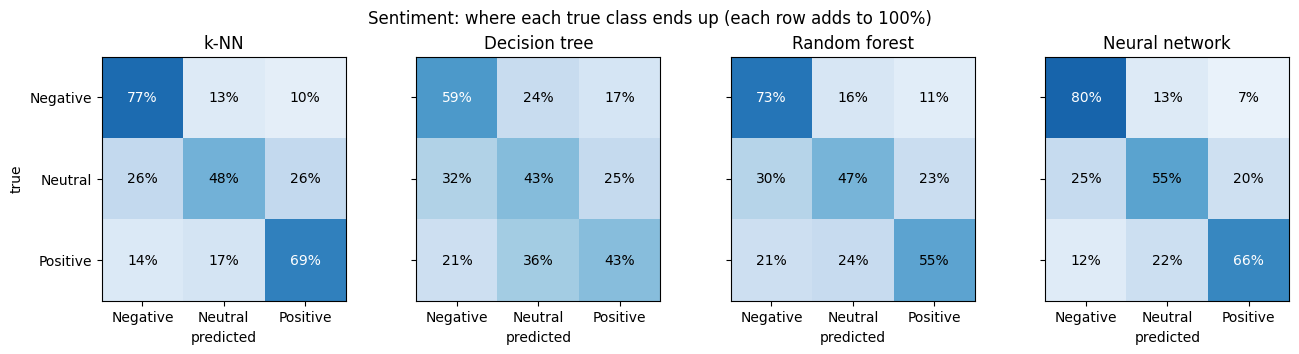

In [88]:
ms = models_with_predictions('sentiment')
fig, axes = plt.subplots(1, len(ms), figsize=(3.4 * len(ms), 3.4), squeeze=False)
for ax, m in zip(axes[0], ms):
    p = load_predictions(m, 'sentiment')
    counts = confusion_matrix(p['true_label'], p['pred_label'], labels=[0, 1, 2])
    share = counts / counts.sum(axis=1, keepdims=True)
    ax.imshow(share, cmap='Blues', vmin=0, vmax=1)
    for i in range(3):
        for j in range(3):
            ax.text(j, i, f'{share[i, j]:.0%}', ha='center', va='center',
                    color='white' if share[i, j] > 0.55 else 'black')
    ax.set_xticks(range(3), SENTIMENT_NAMES)
    ax.set_yticks(range(3), SENTIMENT_NAMES if ax is axes[0][0] else [''] * 3)
    ax.set_xlabel('predicted')
    ax.set_title(MODEL_NAMES[m])
axes[0][0].set_ylabel('true')
fig.suptitle('Sentiment: where each true class ends up (each row adds to 100%)')
fig.tight_layout()
fig.savefig(os.path.join(OUT_DIR, 'confusion_sentiment.png'), dpi=150, bbox_inches='tight')
plt.show()

### 10.3 Image: hardest classes and most-confused pairs
The dataset gives the 50 object classes only as numbers (0 to 49), so they are reported by number. Each class has 80 validation images.

For each model:
- **Worst classes:** the 5 classes with the lowest recall (accuracy).
- **Most-confused pairs:** the 10 pairs of classes the model mixes up most often, counting both directions. `a->b` is the number of class-`a` images predicted as `b`, out of 80.

The per-class accuracy of every model is saved as `per_class_image.csv`. Section 11 uses it.

In [89]:
N_IMAGE = data['image']['n_classes']
image_class_acc = pd.DataFrame(index=range(N_IMAGE))
image_class_acc.index.name = 'class'

for m in models_with_predictions('image'):
    p = load_predictions(m, 'image')
    counts = confusion_matrix(p['true_label'], p['pred_label'], labels=range(N_IMAGE))
    class_acc = counts.diagonal() / counts.sum(axis=1)
    image_class_acc[MODEL_NAMES[m]] = class_acc

    pairs = pd.DataFrame([dict(a=a, b=b, a_to_b=counts[a, b], b_to_a=counts[b, a], total=counts[a, b] + counts[b, a])
                          for a in range(N_IMAGE) for b in range(a + 1, N_IMAGE)])
    pairs = pairs.sort_values('total', ascending=False).head(10)
    pairs = pairs.rename(columns={'a_to_b': 'a->b', 'b_to_a': 'b->a'})

    worst = np.argsort(class_acc)[:5]
    print(f'=== {MODEL_NAMES[m]}: validation accuracy {np.mean(p["true_label"] == p["pred_label"]):.1%} ===')
    print('worst classes:', ', '.join(f'{c} ({class_acc[c]:.0%})' for c in worst))
    print('most-confused pairs:')
    print(pairs.to_string(index=False))
    print()

image_class_acc.to_csv(os.path.join(OUT_DIR, 'per_class_image.csv'))

=== k-NN: validation accuracy 56.3% ===
worst classes: 22 (34%), 41 (39%), 26 (40%), 7 (44%), 29 (44%)
most-confused pairs:
 a  b  a->b  b->a  total
37 39     6     5     11
 2  4     4     4      8
38 39     2     6      8
14 15     1     7      8
12 13     2     6      8
 3  4     3     5      8
12 14     2     5      7
27 38     4     3      7
10 11     3     4      7
 7  8     6     1      7

=== Decision tree: validation accuracy 12.7% ===
worst classes: 30 (1%), 22 (1%), 31 (2%), 6 (4%), 23 (4%)
most-confused pairs:
 a  b  a->b  b->a  total
13 25     5    14     19
 2  3    11     6     17
12 13    12     5     17
 3  4     9     8     17
17 31     1    14     15
 2  4     5     9     14
17 42     3    10     13
 5 48     3    10     13
37 39     4     9     13
16 17    10     2     12

=== Random forest: validation accuracy 26.2% ===
worst classes: 29 (2%), 22 (2%), 24 (4%), 40 (5%), 41 (6%)
most-confused pairs:
 a  b  a->b  b->a  total
 2  4     4    28     32
 2  3     2    24

**Do mistakes go to classes with nearby numbers?** Many of the most-confused pairs have neighbouring numbers (for example 12 and 13, or 37 and 39). If the dataset numbers similar objects next to each other, mistakes should land on nearby numbers more often than chance. "Chance" is the share expected if each mistake went to a random other class. We don't know what the numbers stand for, so this is only a hint about how the classes are ordered.

In [90]:
chance = np.mean([np.mean(np.abs(np.delete(np.arange(N_IMAGE), a) - a) <= 2) for a in range(N_IMAGE)])
print(f'chance: {chance:.1%}')
for m in models_with_predictions('image'):
    p = load_predictions(m, 'image')
    wrong = p[p['true_label'] != p['pred_label']]
    near = np.mean(np.abs(wrong['true_label'] - wrong['pred_label']) <= 2)
    print(f'{MODEL_NAMES[m]:15s} | mistakes that go to a class within 2 numbers: {near:.1%}')

chance: 7.9%
k-NN            | mistakes that go to a class within 2 numbers: 16.7%
Decision tree   | mistakes that go to a class within 2 numbers: 12.3%
Random forest   | mistakes that go to a class within 2 numbers: 15.7%
Neural network  | mistakes that go to a class within 2 numbers: 18.9%


## 11. Mistakes across models
Do the four models fail on the same examples, or on different ones? This matters for two of the mandate's questions: whether the neural network corrects the simpler models' mistakes, and whether averaging models could help (it only can if they make different mistakes).

All four prediction files list the validation rows in the same order (the shared split), which the first cell checks.

In [91]:
def predictions_table(task):
    """One column of predicted labels per model, plus the true labels, for one task."""
    ms = models_with_predictions(task)
    files = {m: load_predictions(m, task) for m in ms}
    for m in ms:
        assert (files[m]['id'] == files[ms[0]]['id']).all(), f'{m}: rows are not in the shared order'
    preds = pd.DataFrame({MODEL_NAMES[m]: files[m]['pred_label'].to_numpy() for m in ms})
    return preds, files[ms[0]]['true_label'].to_numpy()

tables = {task: predictions_table(task) for task in TASKS}
for task in TASKS:
    preds, y = tables[task]
    print(f'{task:9s} | models: {", ".join(preds.columns)} | validation rows: {len(y)}')

image     | models: k-NN, Decision tree, Random forest, Neural network | validation rows: 4000
sentiment | models: k-NN, Decision tree, Random forest, Neural network | validation rows: 2400


### 11.1 Does one model get right what another gets wrong?
Each row is the model that made the mistakes. Each column shows the share of those mistakes that the column's model gets right. For example, the *Decision tree* row, *k-NN* column is: of the rows the tree gets wrong, the percentage that k-NN gets right. The *Neural network* column answers the mandate's question *does the neural network correct mistakes made by simpler classifiers?*

In [92]:
for task in TASKS:
    preds, y = tables[task]
    names = list(preds.columns)
    fixes = pd.DataFrame(index=names, columns=names, dtype=float)
    for a in names:
        a_wrong = preds[a].to_numpy() != y
        for b in names:
            if a != b:
                fixes.loc[a, b] = np.mean(preds[b].to_numpy()[a_wrong] == y[a_wrong])
    print(f'=== {task}: % of the row model\'s mistakes that the column model gets right ===')
    print((fixes * 100).round(1).to_string(na_rep='-'))
    print()

=== image: % of the row model's mistakes that the column model gets right ===
                k-NN  Decision tree  Random forest  Neural network
k-NN               -            6.4           12.0            26.1
Decision tree   53.1              -           20.4            47.7
Random forest   47.8            5.8              -            40.1
Neural network  33.3            5.7            8.7               -

=== sentiment: % of the row model's mistakes that the column model gets right ===
                k-NN  Decision tree  Random forest  Neural network
k-NN               -           29.8           21.6            20.8
Decision tree   51.9              -           42.2            54.5
Random forest   33.5           28.5              -            38.7
Neural network  15.0           28.8           22.4               -



### 11.2 Do models make the same mistakes?
For each pair of models:
- **both wrong:** the share of validation rows that both get wrong
- **if independent:** what that share would be if the two models' mistakes had nothing to do with each other (error rate of one × error rate of the other). If *both wrong* is much higher, the models tend to fail on the same examples.
- **same wrong answer:** of the rows both get wrong, the share where they also pick the same wrong class

In [93]:
for task in TASKS:
    preds, y = tables[task]
    names = list(preds.columns)
    rows = []
    for i, a in enumerate(names):
        for b in names[i + 1:]:
            pa, pb = preds[a].to_numpy(), preds[b].to_numpy()
            a_wrong, b_wrong = pa != y, pb != y
            both = a_wrong & b_wrong
            rows.append({'pair': f'{a} + {b}',
                         'both wrong (%)': 100 * both.mean(),
                         'if independent (%)': 100 * a_wrong.mean() * b_wrong.mean(),
                         'same wrong answer (%)': 100 * np.mean(pa[both] == pb[both]) if both.any() else np.nan})
    print(f'=== {task} ===')
    print(pd.DataFrame(rows).round(1).to_string(index=False))
    print()

=== image ===
                          pair  both wrong (%)  if independent (%)  same wrong answer (%)
          k-NN + Decision tree            40.9                38.2                    4.4
          k-NN + Random forest            38.5                32.3                    9.1
         k-NN + Neural network            32.3                21.2                   14.3
 Decision tree + Random forest            69.5                64.4                   12.3
Decision tree + Neural network            45.7                42.3                    5.0
Random forest + Neural network            44.2                35.7                   14.7

=== sentiment ===
                          pair  both wrong (%)  if independent (%)  same wrong answer (%)
          k-NN + Decision tree            24.8                18.2                   67.9
          k-NN + Random forest            27.7                14.7                   86.1
         k-NN + Neural network            28.0                11.6 

### 11.3 Examples every model gets wrong
These are the hardest examples: no model gets them right. Their ids are saved as `all_wrong_<task>.csv` in case you want to look at them more closely.

In [94]:
for task in TASKS:
    preds, y = tables[task]
    all_wrong = (preds.to_numpy() != y[:, None]).all(axis=1)
    all_right = (preds.to_numpy() == y[:, None]).all(axis=1)
    print(f'=== {task} ({len(preds.columns)} models) ===')
    print(f'every model wrong: {all_wrong.sum()} rows ({all_wrong.mean():.1%}) | '
          f'every model right: {all_right.sum()} rows ({all_right.mean():.1%})')

    ids = load_predictions(models_with_predictions(task)[0], task)['id'].to_numpy()
    pd.DataFrame({'id': ids[all_wrong], 'true_label': y[all_wrong]}).to_csv(
        os.path.join(OUT_DIR, f'all_wrong_{task}.csv'), index=False)

    # which true classes the every-model-wrong rows belong to, compared with all validation rows
    counts = pd.Series(y[all_wrong]).value_counts()
    if task == 'sentiment':
        for c, name in enumerate(SENTIMENT_NAMES):
            print(f'  {name:9s}: {counts.get(c, 0):4d} rows, {counts.get(c, 0) / max(all_wrong.sum(), 1):.0%} '
                  f'of the every-model-wrong rows (each sentiment is 33% of the validation rows)')
    else:
        top = counts.head(5)
        print('  classes with the most every-model-wrong rows (out of 80 images each):',
              ', '.join(f'{c} ({n})' for c, n in top.items()))
    print()

=== image (4 models) ===
every model wrong: 1169 rows (29.2%) | every model right: 275 rows (6.9%)
  classes with the most every-model-wrong rows (out of 80 images each): 41 (40), 22 (37), 14 (35), 29 (35), 26 (34)

=== sentiment (4 models) ===
every model wrong: 424 rows (17.7%) | every model right: 766 rows (31.9%)
  Negative :   67 rows, 16% of the every-model-wrong rows (each sentiment is 33% of the validation rows)
  Neutral  :  198 rows, 47% of the every-model-wrong rows (each sentiment is 33% of the validation rows)
  Positive :  159 rows, 38% of the every-model-wrong rows (each sentiment is 33% of the validation rows)



### 11.4 Which model does best on the hardest classes?
**Image:** the 10 classes with the lowest accuracy, averaged over the models, and each model's accuracy on them (out of 80 images per class). The last line counts how often each model is the best on these classes.

**Sentiment:** the hardest class is Neutral for every model, so the Neutral column of the recall table in 10.1 answers this for sentiment.

In [95]:
per_class = pd.read_csv(os.path.join(OUT_DIR, 'per_class_image.csv'), index_col='class')
hardest = per_class.mean(axis=1).sort_values().head(10).index
hard_table = per_class.loc[hardest]
print('Image: accuracy (%) on the 10 hardest classes')
print((hard_table * 100).round(0).astype(int).to_string())
print()
print('best model on these classes (ties count for each):')
best_counts = (hard_table.to_numpy() == hard_table.max(axis=1).to_numpy()[:, None]).sum(axis=0)
for name, n in zip(hard_table.columns, best_counts):
    print(f'  {name:15s} {n}')

Image: accuracy (%) on the 10 hardest classes
       k-NN  Decision tree  Random forest  Neural network
class                                                    
22       34              1              2              42
41       39              8              6              29
29       44              5              2              40
6        55              4              8              25
14       46              6             15              25
26       40              6             12              35
30       46              1              6              40
9        49              4             10              38
27       48              5              9              40
40       46              4              5              48

best model on these classes (ties count for each):
  k-NN            8
  Decision tree   0
  Random forest   0
  Neural network  2


## 12. Hyperparameter plots
One figure per algorithm, drawn from the sweep tables and training histories saved in Sections 5 to 8. Each figure is also saved to `OUT_DIR` as a PNG for the report. A figure whose data is not saved yet is skipped.

The neural network's hyperparameter sweeps (dropout, learning rate, network size, and so on) are in `nn_experiments.ipynb`. This section plots only its final setups: training curves and the effect of averaging more networks.

In [96]:
COLORS = ['#2a78d6', '#eb6834', '#1baf7a']    # blue, orange, aqua (checked for colour-blind readers)
MARKERS = ['o', 's', '^']                     # a different marker per line, so colour is never the only cue

def style(ax, xlabel, ylabel, title):
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    ax.set_title(title)
    ax.grid(True, color='#e5e5e5', linewidth=0.8)
    ax.spines[['top', 'right']].set_visible(False)

def save_figure(fig, name):
    fig.tight_layout()
    fig.savefig(os.path.join(OUT_DIR, name), dpi=150, bbox_inches='tight')
    plt.show()

def not_run_yet(ax):
    """Blank out a panel whose data is not saved yet."""
    ax.axis('off')
    ax.text(0.5, 0.5, 'not run yet', ha='center', va='center', color='#888888', transform=ax.transAxes)

def at_least_10_points(ax, values):
    """Show at least 10 points of accuracy on the y-axis, so differences within noise don't look large."""
    low, high = min(values), max(values)
    pad = max(0, 10 - (high - low)) / 2
    ax.set_ylim(low - pad - 1, high + pad + 1)

def saved(name):
    """Load a CSV from OUT_DIR, or return None (with a message) if it isn't there yet."""
    path = os.path.join(OUT_DIR, name)
    if not os.path.exists(path):
        print(f'{name} not saved yet, skipping')
        return None
    return pd.read_csv(path)

### 12.1 k-NN: k, distance, scaling and voting
- **Left:** validation accuracy against k (log scale) for each task's best scaling and distance, with both voting types. On image, accuracy is highest at k = 1 and falls as k grows. On sentiment, it keeps rising up to a few thousand neighbours.
- **Right:** the best accuracy reached by each scaling and distance (best k and voting for each cell).

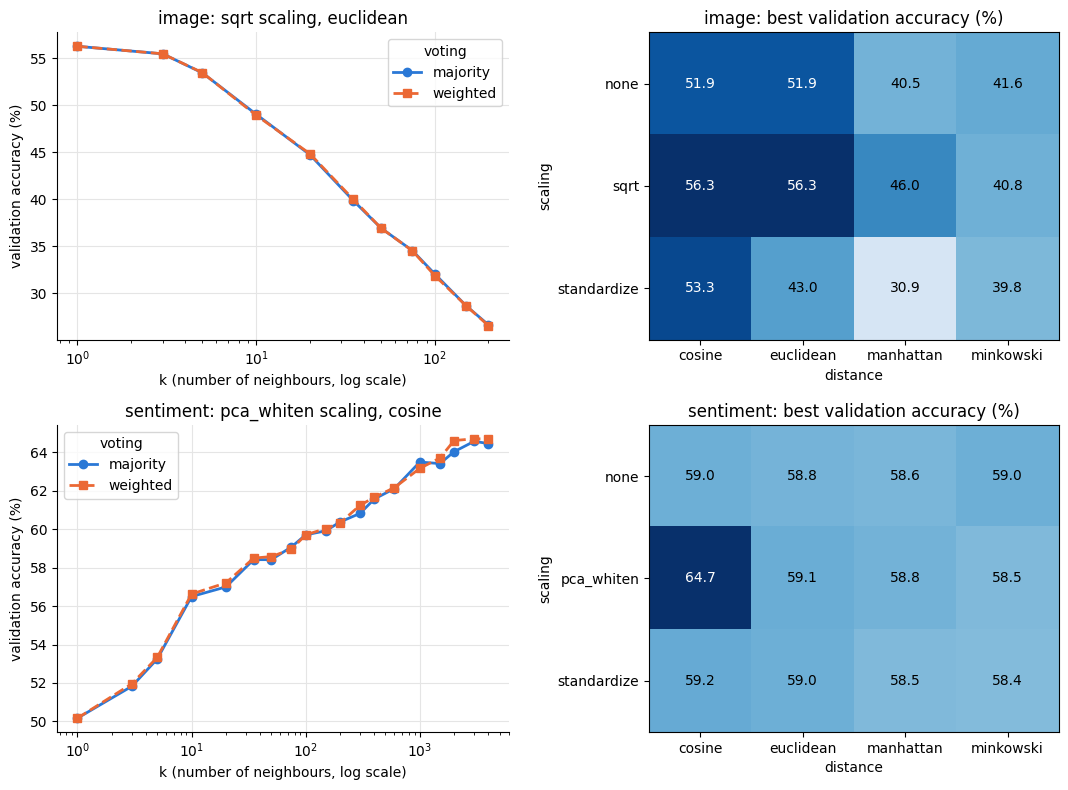

In [97]:
fig, axes = plt.subplots(2, 2, figsize=(11, 8))
for row, task in enumerate(TASKS):
    sweep = saved(f'sweep_knn_{task}.csv')
    if sweep is None:
        not_run_yet(axes[row][0]); not_run_yet(axes[row][1])
        continue
    best = sweep.loc[sweep['val_acc'].idxmax()]
    ax = axes[row][0]
    for i, voting in enumerate(['majority', 'weighted']):
        s = sweep[(sweep['scaling'] == best['scaling']) & (sweep['distance'] == best['distance'])
                  & (sweep['voting'] == voting)]
        ax.plot(s['k'], s['val_acc'] * 100, color=COLORS[i], marker=MARKERS[i], linestyle=['-', '--'][i],
                linewidth=2, markersize=6, label=voting)
    ax.set_xscale('log')
    ax.legend(title='voting')
    style(ax, 'k (number of neighbours, log scale)', 'validation accuracy (%)',
          f"{task}: {best['scaling']} scaling, {best['distance'].replace('_distance', '')}")

    ax = axes[row][1]
    grid = sweep.groupby(['scaling', 'distance'])['val_acc'].max().unstack() * 100
    grid.columns = [c.replace('_distance', '') for c in grid.columns]
    ax.imshow(grid.to_numpy(), cmap='Blues', vmin=grid.to_numpy().min() - 5, vmax=grid.to_numpy().max())
    for i in range(grid.shape[0]):
        for j in range(grid.shape[1]):
            v = grid.iloc[i, j]
            ax.text(j, i, f'{v:.1f}', ha='center', va='center',
                    color='white' if v > grid.to_numpy().max() - 0.4 * (grid.to_numpy().max() - grid.to_numpy().min()) else 'black')
    ax.set_xticks(range(grid.shape[1]), grid.columns)
    ax.set_yticks(range(grid.shape[0]), grid.index)
    ax.set_title(f'{task}: best validation accuracy (%)')
    ax.set_xlabel('distance')
    ax.set_ylabel('scaling')
save_figure(fig, 'plot_knn.png')

### 12.2 Decision tree: depth
Training and validation accuracy against maximum depth, for trees with no limit on node size (6.3). The gap between the two lines is memorization: training accuracy keeps climbing while validation accuracy stays flat (image) or falls (sentiment).

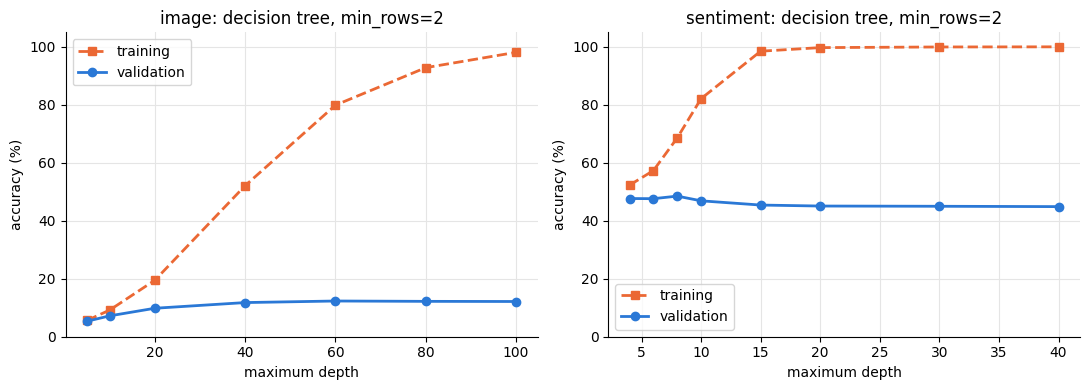

In [98]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, task in zip(axes, TASKS):
    sweep = saved(f'sweep_tree_no_limit_{task}.csv')
    if sweep is None:
        not_run_yet(ax)
        continue
    ax.plot(sweep['max_depth'], sweep['train_acc'] * 100, color=COLORS[1], marker=MARKERS[1], linestyle='--',
            linewidth=2, markersize=6, label='training')
    ax.plot(sweep['max_depth'], sweep['val_acc'] * 100, color=COLORS[0], marker=MARKERS[0],
            linewidth=2, markersize=6, label='validation')
    ax.set_ylim(0, 105)
    ax.legend()
    style(ax, 'maximum depth', 'accuracy (%)', f'{task}: decision tree, min_rows=2')
save_figure(fig, 'plot_tree.png')

### 12.3 Random forest: number of trees and depth
Validation accuracy against the number of trees, one line per depth. For sentiment, the lines use the `min_rows` and `n_features` of the best setting. More trees help at first, then the gains flatten. Compare the forest's training and validation accuracy in Section 9 with the single tree's: the forest also memorizes its training rows, but generalizes much better.

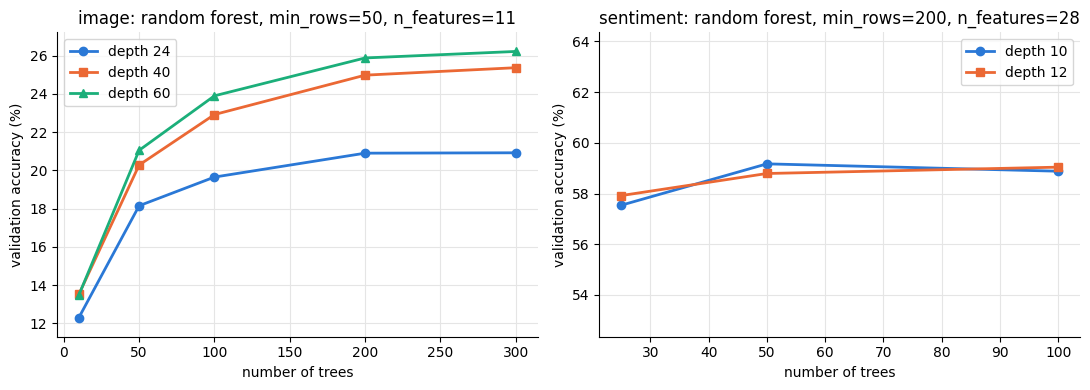

In [99]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, task in zip(axes, TASKS):
    sweep = saved(f'sweep_forest_{task}.csv')
    if sweep is None:
        not_run_yet(ax)
        continue
    best = sweep.loc[sweep['val_acc'].idxmax()]
    s = sweep[(sweep['min_rows'] == best['min_rows']) & (sweep['n_features'] == best['n_features'])]
    for i, depth in enumerate(sorted(s['max_depth'].unique())):
        d = s[s['max_depth'] == depth].sort_values('n_trees')
        ax.plot(d['n_trees'], d['val_acc'] * 100, color=COLORS[i % 3], marker=MARKERS[i % 3],
                linewidth=2, markersize=6, label=f'depth {depth}')
    at_least_10_points(ax, s['val_acc'] * 100)
    ax.legend()
    style(ax, 'number of trees', 'validation accuracy (%)',
          f"{task}: random forest, min_rows={int(best['min_rows'])}, n_features={int(best['n_features'])}")
save_figure(fig, 'plot_forest.png')

### 12.4 Neural network: training curves and averaging
- **Top:** training and validation accuracy per epoch, averaged over the networks. On sentiment, early stopping ends networks at different epochs, so later epochs average fewer networks. Each network keeps the weights from its best validation epoch.
- **Bottom:** validation accuracy when averaging the first 1, 2, ... networks.

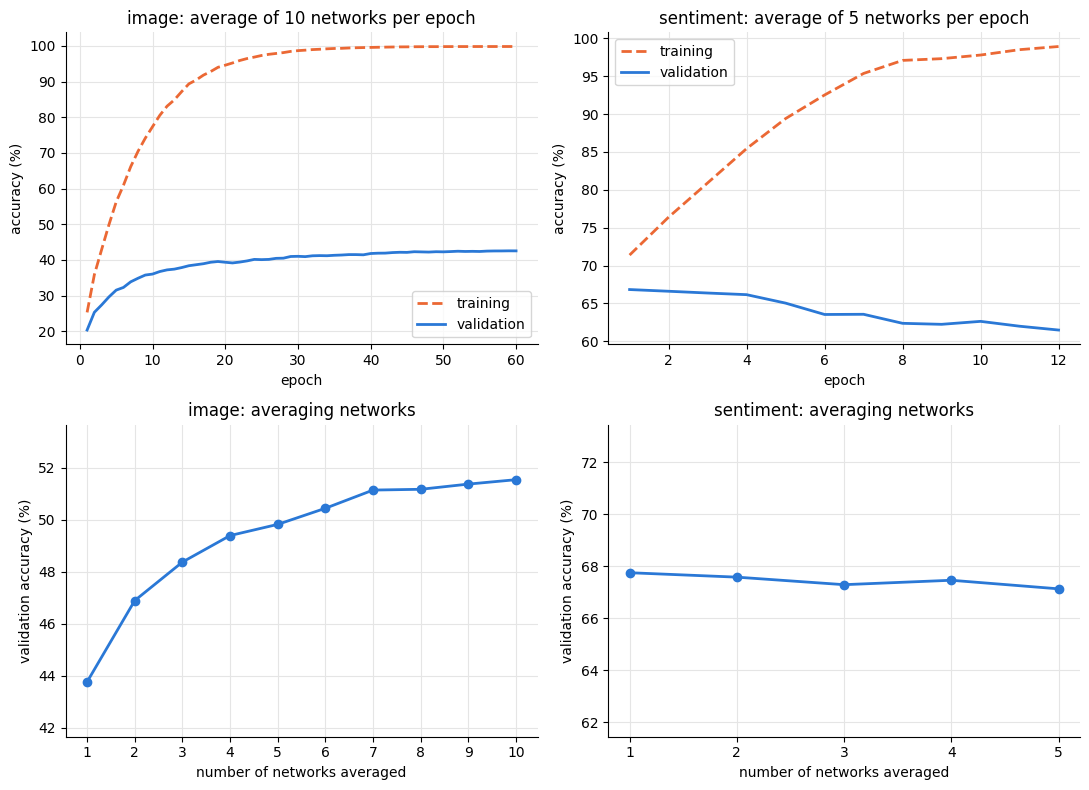

In [100]:
fig, axes = plt.subplots(2, 2, figsize=(11, 8))
for col, task in enumerate(TASKS):
    history = saved(f'history_nn_{task}.csv')
    if history is not None:
        ax = axes[0][col]
        mean = history.groupby('epoch')[['train_acc', 'val_acc']].mean() * 100
        ax.plot(mean.index, mean['train_acc'], color=COLORS[1], linestyle='--', linewidth=2, label='training')
        ax.plot(mean.index, mean['val_acc'], color=COLORS[0], linewidth=2, label='validation')
        ax.legend()
        style(ax, 'epoch', 'accuracy (%)', f'{task}: average of {history["seed"].nunique()} networks per epoch')
    else:
        not_run_yet(axes[0][col])
    curve = saved(f'ensemble_curve_nn_{task}.csv')
    if curve is not None:
        ax = axes[1][col]
        ax.plot(curve['n_networks'], curve['val_acc'] * 100, color=COLORS[0], marker=MARKERS[0],
                linewidth=2, markersize=6)
        ax.set_xticks(curve['n_networks'])
        at_least_10_points(ax, curve['val_acc'] * 100)
        style(ax, 'number of networks averaged', 'validation accuracy (%)', f'{task}: averaging networks')
    else:
        not_run_yet(axes[1][col])
save_figure(fig, 'plot_nn.png')

## 13. Choosing the final model
For each task, the model with the highest validation accuracy on the shared split is the one submitted. The accuracies come from the saved validation predictions, the same numbers as Section 9.

The choice is saved to `final_choice.json`, which Section 14 reads.

In [101]:
import json

NOISE_MARGIN = {'image': 0.015, 'sentiment': 0.02}

final_choice = {}
for task in TASKS:
    rows = []
    for m in models_with_predictions(task):
        p = load_predictions(m, task)
        rows.append(dict(model=m, name=MODEL_NAMES[m], val_acc=float(np.mean(p['pred_label'] == p['true_label']))))
    table = pd.DataFrame(rows).sort_values('val_acc', ascending=False).reset_index(drop=True)
    best, runner_up = table.iloc[0], table.iloc[1]
    final_choice[task] = dict(model=best['model'], name=best['name'], val_acc=best['val_acc'])

    print(f'=== {task} ===')
    print(table[['name', 'val_acc']].assign(val_acc=lambda t: (t['val_acc'] * 100).round(1))
          .rename(columns={'name': 'model', 'val_acc': 'validation accuracy (%)'}).to_string(index=False))
    gap = best['val_acc'] - runner_up['val_acc']
    tie = 'within the noise margin, effectively a tie' if gap <= NOISE_MARGIN[task] else 'beyond the noise margin'
    print(f"CHOSEN: {best['name']} ({best['val_acc']:.1%}), {gap * 100:.1f} points ahead of {runner_up['name']} ({tie})\n")

with open(os.path.join(OUT_DIR, 'final_choice.json'), 'w') as f:
    json.dump(final_choice, f, indent=2)
overall = np.mean([final_choice[t]['val_acc'] for t in TASKS])
print(f'expected overall score (image + sentiment) / 2 on validation: {overall:.4f}')

=== image ===
         model  validation accuracy (%)
          k-NN                     56.3
Neural network                     51.6
 Random forest                     26.2
 Decision tree                     12.7
CHOSEN: k-NN (56.3%), 4.7 points ahead of Neural network (beyond the noise margin)

=== sentiment ===
         model  validation accuracy (%)
Neural network                     67.1
          k-NN                     64.7
 Random forest                     58.4
 Decision tree                     48.5
CHOSEN: Neural network (67.1%), 2.4 points ahead of k-NN (beyond the noise margin)

expected overall score (image + sentiment) / 2 on validation: 0.6170


## 14. Final model and Kaggle submission
Retrain the chosen model(s) on **all** the training data, then predict the test set. For the neural network, there is no validation set to pick the best epoch, so it trains for a fixed number of epochs: 60 for image (after checking that the last epoch scores about the same as the best one), and for sentiment each network's best validation epoch from Section 8 (1 or 2).

The submission follows the order of `sample_submission.csv`, with a check that all 10,000 ids have a label.

**Known issue (found after submitting):** in `train_model` (Section 8.1), the two `keep_last_epoch` lines are indented inside the epoch loop, so with `keep_last_epoch=True` a network stops after its first epoch. The submitted sentiment networks therefore trained for 1 epoch each instead of 1 or 2. The code is left as it was when the submission was made. The fix is to move those two lines out of the loop, just above `model.load_state_dict(best['state'])`. The validation results in Section 8 are not affected, because they don't use `keep_last_epoch`.


### 14.1 Retrain on all the training rows and predict the test set
`nn_prepare_full` is `nn_prepare` from 8.2 with all the training rows instead of the training part, so the scaling statistics come from all of them. `train_model` still needs something in its validation slot. It gets the first 2,000 training rows, but with `keep_last_epoch=True` and no early stopping, they decide nothing.

In [105]:
import inspect
assert 'keep_last_epoch' in inspect.getsource(train_model), \
    'train_model is the old version: run the train_model cell in Section 8.1 of this notebook first'

with open(os.path.join(OUT_DIR, 'final_choice.json')) as f:
    final_choice = json.load(f)

def nn_epochs(task):
    """The number of epochs for each seed when training on all the data, from the Section 8 histories."""
    cfg = NN_FINAL_CFG[task]
    history = pd.read_csv(os.path.join(OUT_DIR, f'history_nn_{task}.csv'))
    best = history.loc[history.groupby('seed')['val_acc'].idxmax()].set_index('seed')
    if cfg.get('cosine', False):
        last = history[history['epoch'] == cfg['epochs']].set_index('seed')
        print(f"{task}: best validation epoch {best['val_acc'].mean():.1%} on average, "
              f"last epoch ({cfg['epochs']}) {last['val_acc'].mean():.1%}: using the last epoch")
        return {s: cfg['epochs'] for s in NN_SEEDS[task]}
    epochs = {s: int(best.loc[s, 'epoch']) for s in NN_SEEDS[task]}
    print(f'{task}: epochs per seed (its best validation epoch in Section 8): {epochs}')
    return epochs

def nn_prepare_full(task, scaling):
    """Like nn_prepare (8.2), but with all the training rows: scaling statistics come from all of them."""
    X_tr, y_tr = data[task]['X'].astype(np.float32), data[task]['y'].astype(np.int64)
    X_te = data[task]['X_test'].astype(np.float32)
    if scaling.startswith('sqrt'):
        X_tr, X_te = np.sqrt(X_tr), np.sqrt(X_te)
    if 'l2' in scaling:
        X_tr, X_te = l2_normalize(X_tr), l2_normalize(X_te)
    if 'standardize' in scaling:
        mean, std = X_tr.mean(axis=0), X_tr.std(axis=0) + 1e-8
        X_tr, X_te = (X_tr - mean) / std, (X_te - mean) / std
    f32 = lambda A: np.ascontiguousarray(A, dtype=np.float32)
    return dict(X_tr=f32(X_tr), y_tr=y_tr, X_va=f32(X_tr[:2000]), y_va=y_tr[:2000],   # placeholder slot, decides nothing
                X_test=f32(X_te), test_ids=data[task]['test_ids'], n_classes=data[task]['n_classes'], scaling=scaling)

def test_probs_nn(task):
    """Train the task's networks on all the training rows and average their test probabilities."""
    d = nn_prepare_full(task, NN_SCALING[task])
    probs = []
    for s, epochs in nn_epochs(task).items():
        print(f'training: {task} | seed {s} | {epochs} epochs')
        cfg = {**NN_FINAL_CFG[task], 'seed': s, 'epochs': epochs, 'patience': epochs, 'keep_last_epoch': True}
        model, _, _ = train_model(d, cfg, verbose=False)
        probs.append(predict_proba(model, d['X_test']))
    return np.mean(probs, axis=0)

def test_probs_knn(task):
    """k-NN with its best Section 5 setting, using all the training rows; vote shares for the test rows."""
    best = knn_sweeps[task].loc[knn_sweeps[task]['val_acc'].idxmax()]
    scaling, distance, k, voting = best['scaling'], best['distance'], int(best['k']), best['voting']
    print(f'{task}: k-NN with scaling={scaling}, distance={distance}, k={k}, voting={voting}')
    X_a, X_b = dict(KNN_SCALINGS[task])[scaling](data[task]['X'], data[task]['X_test'])   # learned on all training rows
    X_a, X_b = X_a.astype(np.float32), X_b.astype(np.float32)
    idx, dist = nearest_neighbours(X_a, X_b, distance_by_name[distance], k)
    _, probs = knn_vote(data[task]['y'], idx, dist, k, voting == 'weighted', data[task]['n_classes'], with_shares=True)
    return probs

TEST_PROBS = {'nn': test_probs_nn, 'knn': test_probs_knn}

test_pred = {}
for task in TASKS:
    model = final_choice[task]['model']
    if model not in TEST_PROBS:
        raise NotImplementedError('Section 14 retrains only k-NN and the neural network')
    path = os.path.join(OUT_DIR, f'test_probs_{model}_{task}.npy')
    if os.path.exists(path):
        print(f'{model} / {task}: test probabilities already saved, loading')
        probs = np.load(path)
    else:
        start = time.time()
        probs = TEST_PROBS[model](task)
        np.save(path, probs)
        print(f'{model} / {task}: done in {time.time() - start:.0f} s')
    test_pred[task] = probs.argmax(axis=1)
    print(f"{task}: {final_choice[task]['name']}, {len(test_pred[task])} test predictions\n")

image: k-NN with scaling=sqrt, distance=euclidean_distance, k=1, voting=majority
knn / image: done in 92 s
image: k-NN, 5000 test predictions

sentiment: epochs per seed (its best validation epoch in Section 8): {0: 1, 1: 2, 2: 2, 3: 1, 4: 2}
training: sentiment | seed 0 | 1 epochs
training: sentiment | seed 1 | 2 epochs
training: sentiment | seed 2 | 2 epochs
training: sentiment | seed 3 | 1 epochs
training: sentiment | seed 4 | 2 epochs
nn / sentiment: done in 2 s
sentiment: Neural network, 5000 test predictions



### 14.2 Write the submission
Same steps as the code on the Kaggle page: put both tasks' predictions together, then follow the row order of `sample_submission.csv`, with checks that every id gets exactly one label.

**Sanity check:** the test set has 100 images per image class, so the predicted counts per class should be roughly even. A class predicted far more or less than 100 times would point to a problem.

In [106]:
sample = pd.read_csv(find_csv('sample_submission.csv'))
predictions = pd.concat([pd.DataFrame({'id': data[task]['test_ids'], 'label': test_pred[task]}) for task in TASKS],
                        ignore_index=True)
submission = sample[['id']].merge(predictions, on='id', how='left', validate='one_to_one')
assert len(submission) == len(sample) == 10000, 'need one row per test id'
assert submission['label'].notna().all(), 'some ids have no prediction'
submission['label'] = submission['label'].astype(int)

path = os.path.join(OUT_DIR, 'submission_final.csv')
submission.to_csv(path, index=False)
print('saved:', path)
print(submission.head())

image_counts = np.bincount(test_pred['image'], minlength=data['image']['n_classes'])
print(f'\nimage: predictions per class: min {image_counts.min()}, max {image_counts.max()} (true: 100 each)')
print('sentiment: predictions per class (Negative, Neutral, Positive):',
      np.bincount(test_pred['sentiment'], minlength=3).tolist())

saved: /content/drive/MyDrive/comp472/comparison/submission_final.csv
            id  label
0  text_003234      2
1  text_004517      1
2   img_000140     26
3   img_004880     16
4  text_002494      0

image: predictions per class: min 64, max 149 (true: 100 each)
sentiment: predictions per class (Negative, Neutral, Positive): [2414, 1380, 1206]
